# Uzbek paraphrase detection: a PARAPHRASUS-style evaluation

We fine-tune several pretrained encoders as **cross-encoders** (both sentences go into the model together)
on our Uzbek paraphrase data and compare them with simple logistic-regression baselines.
Following the PARAPHRASUS idea, we do not trust one accuracy number: we also look at a strict
"paraphrase vs rest" view, breakdowns by sub-strategy and domain, and grouped bootstrap confidence intervals.

**Privacy rules (always):**
- The data stays on this machine. No cell prints sentences, only counts and metrics.
- Files that contain sentences (error analysis) are written only to `PRIVATE_OUT`, which is outside the project.
- Training and evaluation run fully offline (`HF_HUB_OFFLINE=1`, no wandb, no telemetry).

**How to run:** edit cell 1 (paths, `QUICK`), then run the cells in order. Start with `QUICK = True`.
Cells 1 to 4 only check the environment and the data.

## 1. Configuration (the only cell you normally edit)

In [1]:
import os

# --- Privacy: no network, no telemetry, no experiment trackers ---
# These must be set BEFORE transformers / huggingface_hub are imported.
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["WANDB_DISABLED"] = "true"
os.environ["WANDB_MODE"] = "disabled"
os.environ["DO_NOT_TRACK"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# --- Paths ---
# The private data and the private outputs must live OUTSIDE the project folder.
DATA_DIR = r"C:\Users\iutadmin\Desktop\uzbek_private_data"  #test.csv, dev.csv, test.csv
PRIVATE_OUT = r"C:\Users\iutadmin\Desktop\uzbek_private_data\out"  # error-analysis files WITH sentences go here
MODELS_DIR = "models"     # relative to the project folder (filled by download_models.py)
RESULTS_DIR = "results"   # metrics and logits only, never text
FIGS_DIR = "figs"

# --- Run mode ---
QUICK = False  # True = pipeline test (2,000 train rows, 1 epoch, 1 seed). False = full experiment.

SEEDS = [42] if QUICK else [42, 43, 44]
NUM_EPOCHS = 1 if QUICK else 4
QUICK_TRAIN_ROWS = 2000
RUN_TAG = "quick" if QUICK else "all"  # results go to results/results_<RUN_TAG>.csv

# --- Training protocol (same for every model) ---
MAX_LENGTH = 160
WARMUP_RATIO = 0.10
WEIGHT_DECAY = 0.01
EVAL_BATCH_SIZE = 64
COLLAPSE_THRESHOLD = 0.40  # dev macro-F1 below this = "collapsed" run (reported, not hidden)
FORCE_RERUN = False        # False = skip (model, seed) runs that already finished (crash-safe resume)

# --- Evaluation ---
N_BOOTSTRAP = 1000
LABELS = ["paraphrase", "near_miss", "not_paraphrase"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}

# --- Models: local folder name in models/ -> settings ---
MODELS = {
    "mbert":          {"hf_id": "bert-base-multilingual-cased",       "lr": 2e-5, "batch_size": 32, "grad_accum": 1},
    "xlmr-base":      {"hf_id": "xlm-roberta-base",                   "lr": 2e-5, "batch_size": 32, "grad_accum": 1},
    "xlmr-large":     {"hf_id": "xlm-roberta-large",                  "lr": 1e-5, "batch_size": 8,  "grad_accum": 2},
    "mdeberta":       {"hf_id": "microsoft/mdeberta-v3-base",         "lr": 2e-5, "batch_size": 16, "grad_accum": 1, "bf16": False},
    "bge-m3":         {"hf_id": "BAAI/bge-m3",                        "lr": 1e-5, "batch_size": 8,  "grad_accum": 2},
    "tahrirchi-bert": {"hf_id": "tahrirchi/tahrirchi-bert-base",      "lr": 2e-5, "batch_size": 32, "grad_accum": 1},
    "bertbek":        {"hf_id": "elmurod1202/bertbek-news-big-cased", "lr": 2e-5, "batch_size": 32, "grad_accum": 1},
}
# Which models this machine should train. On the 12 GB GPU the two large ones may run out of memory;
# run them on the H200 cluster by setting e.g. MODELS_TO_RUN = ["xlmr-large", "bge-m3"] there.
MODELS_TO_RUN = ["mbert", "xlmr-base", "mdeberta", "tahrirchi-bert", "bertbek", "xlmr-large", "bge-m3"]

print("Mode:", "QUICK pipeline test" if QUICK else "FULL experiment", "| seeds:", SEEDS, "| epochs:", NUM_EPOCHS)

Mode: FULL experiment | seeds: [42, 43, 44] | epochs: 4


## 2. Environment check
Checks that every library can be loaded (the Application Control policy may block compiled files),
that the notebook kernel is the venv (a past problem), that the GPU works,
that the offline flags are set and that the private folders are outside the project.

In [2]:
import importlib
import platform
import sys

# 2a. Can every library be loaded? The university's Application Control policy blocks some compiled files.
#     If something fails here, do not work around it: ask IT to allow the venv's site-packages folder.
print("Library check:")
blocked = []
for module in ["numpy", "pandas", "torch", "tokenizers", "safetensors", "sentencepiece", "transformers",
               "matplotlib.pyplot", "seaborn"]:
    try:
        importlib.import_module(module)
        print(f"  ok      {module}")
    except Exception as e:  # a blocked file shows up as ImportError or OSError
        blocked.append(module)
        print(f"  FAILED  {module}: {type(e).__name__}: {str(e)[:150]}")
if "torch" in blocked:
    raise RuntimeError("torch cannot be loaded (see the library check above). Ask IT before continuing.")
print()

import torch
import transformers

print("Python executable :", sys.executable)
print("Working directory :", os.getcwd())
print("Python version    :", platform.python_version())
print("torch             :", torch.__version__, "| built for CUDA", torch.version.cuda)
print("transformers      :", transformers.__version__)
print("CUDA available    :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU               :", torch.cuda.get_device_name(0))
    print("bf16 supported    :", torch.cuda.is_bf16_supported())
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print(f"GPU memory        : {free_bytes / 1e9:.1f} GB free of {total_bytes / 1e9:.1f} GB")
    x = torch.randn(1024, 1024, device="cuda")
    print("GPU matmul test   :", "ok" if torch.isfinite(x @ x).all().item() else "FAILED")
    del x

# Warnings for the known setup mistakes
if sys.prefix == sys.base_prefix:
    print("WARNING: this kernel is not a virtual environment. Select the venv kernel (C:\\Users\\iutadmin\\venv).")
if os.path.abspath(sys.prefix).lower().startswith(os.path.abspath(os.getcwd()).lower()):
    print("WARNING: this kernel is the project's own .venv (empty). Select C:\\Users\\iutadmin\\venv instead.")
if not torch.cuda.is_available():
    print("WARNING: no GPU visible. Training would be very slow.")

for flag in ["HF_HUB_OFFLINE", "TRANSFORMERS_OFFLINE", "WANDB_DISABLED", "HF_HUB_DISABLE_TELEMETRY"]:
    print(f"{flag} = {os.environ.get(flag)}")


def is_inside_project(path):
    """True if `path` is inside the current project folder."""
    project = os.path.abspath(os.getcwd())
    try:
        return os.path.commonpath([project, os.path.abspath(path)]) == project
    except ValueError:  # different drives on Windows
        return False


# Privacy guard: private folders must be outside the project folder
for name, path in [("DATA_DIR", DATA_DIR), ("PRIVATE_OUT", PRIVATE_OUT)]:
    if is_inside_project(path):
        raise ValueError(f"{name} must be OUTSIDE the project folder (privacy rule).")

print("Data folder found :", os.path.isdir(DATA_DIR))
for split in ["train", "dev", "test"]:
    print(f"  {split}.csv found :", os.path.isfile(os.path.join(DATA_DIR, f"{split}.csv")))
print("Models downloaded :", [m for m in MODELS if os.path.isdir(os.path.join(MODELS_DIR, m))])
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGS_DIR, exist_ok=True)

Library check:
  ok      numpy
  ok      pandas
  ok      torch
  ok      tokenizers
  ok      safetensors
  ok      sentencepiece


c:\Users\iutadmin\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ok      transformers
  ok      matplotlib.pyplot
  ok      seaborn

Python executable : c:\Users\iutadmin\venv\Scripts\python.exe
Working directory : c:\uzbek-paraphrase
Python version    : 3.12.10
torch             : 2.11.0+cu128 | built for CUDA 12.8
transformers      : 5.22.1
CUDA available    : True
GPU               : NVIDIA GeForce RTX 5070
bf16 supported    : True
GPU memory        : 11.6 GB free of 12.8 GB
GPU matmul test   : ok
HF_HUB_OFFLINE = 1
TRANSFORMERS_OFFLINE = 1
WANDB_DISABLED = true
HF_HUB_DISABLE_TELEMETRY = 1
Data folder found : True
  train.csv found : True
  dev.csv found : True
  test.csv found : True
Models downloaded : ['mbert', 'xlmr-base', 'xlmr-large', 'mdeberta', 'bge-m3', 'tahrirchi-bert', 'bertbek']


## 3. Load and clean the data
Cleaning steps, applied to both sentence columns in every split:
1. **Mojibake repair**: UTF-8 text that was wrongly decoded as Windows-1252 (e.g. `Ñ…` becomes `х`).
   Only character runs that decode to valid UTF-8 are changed.
2. Unicode NFC normalization.
3. **Apostrophes**: every apostrophe variant (`ʻ ʼ ’ ‘ \``, etc.) becomes the straight `'`.
   Cell 7 later picks, per model, the apostrophe form that its tokenizer handles best.
4. **Cyrillic look-alikes**: only in words that mix Latin and Cyrillic letters and are mostly Latin,
   Cyrillic look-alike letters (а е о р с у х ...) are replaced by their Latin twins.

**Gold label for evaluation** = `verified_label` when present and valid, otherwise `label`.
Training always uses the original `label`. Only counts are printed.

In [3]:
import hashlib
import re
import unicodedata
from functools import lru_cache

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

# ---------- (1) mojibake ----------
# Map each Windows-1252 character back to the byte it came from.
_CHAR_TO_BYTE = {}
for _b in range(256):
    try:
        _CHAR_TO_BYTE[bytes([_b]).decode("cp1252")] = _b
    except UnicodeDecodeError:
        _CHAR_TO_BYTE[chr(_b)] = _b      # 5 bytes are undefined in cp1252; Windows keeps them as-is
for _b in range(0x80, 0xA0):
    _CHAR_TO_BYTE.setdefault(chr(_b), _b)  # also handle text decoded as Latin-1


def _char_class(byte_values):
    return "[" + "".join(re.escape(c) for c, b in _CHAR_TO_BYTE.items() if b in byte_values) + "]"


_CONT = _char_class(range(0x80, 0xC0))  # characters that stand for UTF-8 continuation bytes
# One match = the characters that one original UTF-8 character turned into (2, 3 or 4 of them)
_MOJIBAKE_CHAR = re.compile(
    _char_class(range(0xC2, 0xE0)) + _CONT
    + "|" + _char_class(range(0xE0, 0xF0)) + _CONT + "{2}"
    + "|" + _char_class(range(0xF0, 0xF5)) + _CONT + "{3}"
)
_MOJIBAKE_HINT = re.compile("[ÃÂÐÑâËÊ][\u0080-\u00bf\u0152\u0153\u0160\u0161\u0178\u017d\u017e\u0192\u02c6\u02dc\u2013-\u2122]")


def fix_mojibake(text):
    """Repair 'Ñ…' -> 'х', 'â€™' -> '’'. Character runs that are not valid UTF-8 stay unchanged."""
    def repair(match):
        try:
            return bytes(_CHAR_TO_BYTE[c] for c in match.group(0)).decode("utf-8")
        except UnicodeDecodeError:
            return match.group(0)
    return _MOJIBAKE_CHAR.sub(repair, text)


# ---------- (3) apostrophes ----------
APOSTROPHE_VARIANTS = "'`´ʹʻʼʽʾʿˈˊ‘’‚‛′＇"
_APOSTROPHE_RE = re.compile("[" + re.escape(APOSTROPHE_VARIANTS) + "]")


def normalize_apostrophes(text):
    return _APOSTROPHE_RE.sub("'", text)


# ---------- (4) Cyrillic look-alikes inside Latin words ----------
CYRILLIC_TO_LATIN = str.maketrans({
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y", "х": "x", "к": "k",
    "і": "i", "ј": "j", "ѕ": "s", "һ": "h", "ԁ": "d", "ԛ": "q", "ԝ": "w",
    "А": "A", "В": "B", "Е": "E", "К": "K", "М": "M", "Н": "H", "О": "O", "Р": "P",
    "С": "C", "Т": "T", "Х": "X", "У": "Y", "І": "I", "Ј": "J", "Ѕ": "S", "Һ": "H",
})
_LETTER_RUN = re.compile(r"[^\W\d_]+")


@lru_cache(maxsize=None)
def script_of(ch):
    name = unicodedata.name(ch, "")
    if name.startswith("LATIN"):
        return "latin"
    if name.startswith("CYRILLIC"):
        return "cyrillic"
    return "other"


def _count_scripts(word):
    scripts = [script_of(c) for c in word]
    return scripts.count("latin"), scripts.count("cyrillic")


def fix_mixed_script_words(text):
    def repair(match):
        word = match.group(0)
        n_latin, n_cyrillic = _count_scripts(word)
        if n_latin == 0 or n_cyrillic == 0 or n_cyrillic > n_latin:
            return word  # pure word, or mostly Cyrillic: leave it alone
        return word.translate(CYRILLIC_TO_LATIN)
    return _LETTER_RUN.sub(repair, text)


def count_mixed_script_words(text):
    return sum(1 for w in _LETTER_RUN.findall(text) if min(_count_scripts(w)) > 0)


def clean_text_column(series):
    """Apply all cleaning steps; return the cleaned column and how many cells each step changed."""
    s0 = series.fillna("").astype(str)
    s1 = s0.map(lambda t: fix_mojibake(fix_mojibake(t)))  # twice, in case text was garbled twice
    s2 = s1.map(lambda t: unicodedata.normalize("NFC", t))
    s3 = s2.map(normalize_apostrophes)
    s4 = s3.map(fix_mixed_script_words)
    s5 = s4.str.replace(r"\s+", " ", regex=True).str.strip()
    counts = {
        "mojibake_fixed": int((s1 != s0).sum()),
        "apostrophe_changed": int((s3 != s2).sum()),
        "lookalike_fixed": int((s4 != s3).sum()),
        "mixed_words_left": int(s5.map(count_mixed_script_words).sum()),
        "mojibake_suspect_left": int(s5.str.contains(_MOJIBAKE_HINT).sum()),
        "empty": int((s5 == "").sum()),
    }
    return s5, counts


# ---------- loading ----------
REQUIRED_COLUMNS = ["sentence_1", "sentence_2", "label", "domain", "sub_strategy", "source_sentence_id"]
EVAL_COLUMNS = ["verified", "verified_label"]


def normalize_label(series):
    return (series.astype(str).str.strip().str.lower()
            .str.replace("-", "_", regex=False).str.replace(" ", "_", regex=False))


def load_split(split, cleaning_report):
    path = os.path.join(DATA_DIR, f"{split}.csv")
    df = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    expected = REQUIRED_COLUMNS + (EVAL_COLUMNS if split != "train" else [])
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"{split}.csv is missing columns: {missing}")
    n_extra = sum(c not in REQUIRED_COLUMNS + EVAL_COLUMNS for c in df.columns)
    if n_extra:
        print(f"note: {split}.csv has {n_extra} extra column(s); names not printed")
    n_raw = len(df)

    for col in ["sentence_1", "sentence_2"]:
        df[col], counts = clean_text_column(df[col])
        cleaning_report.append({"split": split, "column": col, **counts})
    for col in ["domain", "sub_strategy", "source_sentence_id"]:
        df[col] = df[col].str.strip()
    df["label"] = normalize_label(df["label"])

    if "verified" in df.columns:
        v = df["verified"].str.strip().str.lower()
        df["verified_raw_unparsed"] = ~v.isin(["true", "false", "1", "0", "1.0", "0.0", "yes", "no", ""])
        df["verified"] = v.isin(["true", "1", "1.0", "yes"])
        df["verified_label"] = normalize_label(df["verified_label"])
        has_valid_verified = df["verified_label"].isin(LABELS)
        df["gold"] = df["verified_label"].where(has_valid_verified, df["label"])
        df["gold_from_verified"] = has_valid_verified
    else:
        df["gold"] = df["label"]

    # Drop rows whose label cannot be used (counted, never shown)
    usable = df["label"].isin(LABELS) if split == "train" else df["gold"].isin(LABELS)
    df = df[usable].reset_index(drop=True)
    df["label_id"] = df["label"].map(LABEL2ID).fillna(-1).astype(int)
    df["gold_id"] = df["gold"].map(LABEL2ID).astype(int)
    print(f"{split:5s}: {n_raw} rows read, {n_raw - len(df)} dropped (unusable label), {len(df)} kept")
    return df


cleaning_report = []
train_df = load_split("train", cleaning_report)
dev_df = load_split("dev", cleaning_report)
test_df = load_split("test", cleaning_report)
SPLITS = {"train": train_df, "dev": dev_df, "test": test_df}

print("\nCleaning report (number of cells changed / found):")
display(pd.DataFrame(cleaning_report).set_index(["split", "column"]))


def data_fingerprint():
    """Short hash of the cleaned data. It is stored with every run, so results computed on other data
    (for example the fake test data) are never mixed with results on the real data."""
    h = hashlib.sha256()
    for df in SPLITS.values():
        h.update("\n".join(df["sentence_1"] + "\t" + df["sentence_2"] + "\t" + df["gold"]).encode("utf-8"))
    return h.hexdigest()[:12]


DATA_FINGERPRINT = data_fingerprint()
print("Data fingerprint:", DATA_FINGERPRINT)

train: 15376 rows read, 0 dropped (unusable label), 15376 kept
dev  : 1920 rows read, 0 dropped (unusable label), 1920 kept
test : 1941 rows read, 0 dropped (unusable label), 1941 kept

Cleaning report (number of cells changed / found):


mojibake_fixed  apostrophe_changed  lookalike_fixed  mixed_words_left  mojibake_suspect_left  empty
split column                                                                                                         
train sentence_1               0                   0              129                 0                      0      0
      sentence_2               0                  32              118                22                      0      0
dev   sentence_1               0                  12                0                 0                      0      0
      sentence_2               0                   7                7                 1                      0      0
test  sentence_1               0                   6               23                 0                      0      0
      sentence_2               0                  11               20                 3                      0      0

Data fingerprint: 7433361ad05e


## 4. Privacy-safe data checks (counts only)
Label distributions, sub-strategies, domains, the label vs verified_label crosstab,
source-ID overlap between splits, duplicate pairs and simple length statistics.
Category values that look like free text (long strings) are shown as `(unexpected value)`,
so a broken CSV can never leak a sentence into the output.

In [4]:
def safe_category(series, max_len=40, max_words=4):
    """Return the column with long / text-like values replaced by '(unexpected value)'."""
    s = series.astype(str)
    looks_categorical = (s.str.len() <= max_len) & (s.str.split().str.len() <= max_words)
    return s.where(looks_categorical, "(unexpected value)").replace("", "(empty)")


print("=== 4.1 Label distribution ===")
label_table = pd.DataFrame({
    "train (label)": train_df["label"].value_counts(),
    "dev (label)": dev_df["label"].value_counts(),
    "dev (gold)": dev_df["gold"].value_counts(),
    "test (label)": test_df["label"].value_counts(),
    "test (gold)": test_df["gold"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
label_table.loc["TOTAL"] = label_table.sum()
display(label_table)

for split, df in SPLITS.items():
    print(f"\n=== 4.2 sub_strategy x label ({split}) ===")
    display(pd.crosstab(safe_category(df["sub_strategy"]), safe_category(df["label"]),
                        margins=True, margins_name="TOTAL"))

print("\n=== 4.3 Domain counts ===")
display(pd.DataFrame({split: safe_category(df["domain"]).value_counts() for split, df in SPLITS.items()})
        .fillna(0).astype(int))

for split in ["dev", "test"]:
    df = SPLITS[split]
    print(f"\n=== 4.4 Verification ({split}) ===")
    print("verified=True rows             :", int(df["verified"].sum()), "of", len(df))
    print("verified values not parseable  :", int(df["verified_raw_unparsed"].sum()))
    vl = df["verified_label"].where(df["verified_label"].isin(LABELS) | (df["verified_label"] == ""), "(invalid)")
    print("non-empty but invalid verified_label:", int((vl == "(invalid)").sum()))
    print("gold differs from label         :", int((df["gold"] != df["label"]).sum()))
    print("crosstab label (rows) x verified_label (columns):")
    display(pd.crosstab(safe_category(df["label"]), vl.replace("", "(empty)"), margins=True, margins_name="TOTAL"))
    print("crosstab verified x has verified_label:")
    display(pd.crosstab(df["verified"], df["verified_label"] != "", colnames=["has verified_label"]))

print("\n=== 4.5 source_sentence_id overlap between splits ===")
ids = {split: set(df["source_sentence_id"]) - {""} for split, df in SPLITS.items()}
for split, df in SPLITS.items():
    group_sizes = df.groupby("source_sentence_id").size()
    print(f"{split:5s}: {len(ids[split])} unique IDs, {int((df['source_sentence_id'] == '').sum())} rows without ID, "
          f"pairs per ID: mean {group_sizes.mean():.2f}, max {group_sizes.max()}")
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    shared = ids[a] & ids[b]
    n_rows_b = int(SPLITS[b]["source_sentence_id"].isin(shared).sum())
    print(f"{a} & {b}: {len(shared)} shared IDs -> {n_rows_b} {b} rows come from a source also in {a}")
for split in ["dev", "test"]:  # used later as an extra breakdown
    SPLITS[split]["source_in_train"] = SPLITS[split]["source_sentence_id"].isin(ids["train"])


print("\n=== 4.6 Duplicate pairs (exact, after cleaning) ===")
def pair_keys(df, swapped=False):
    a, b = (df["sentence_2"], df["sentence_1"]) if swapped else (df["sentence_1"], df["sentence_2"])
    return set(a + "\x00" + b)


for split, df in SPLITS.items():
    keys = df["sentence_1"] + "\x00" + df["sentence_2"]
    print(f"{split:5s}: {int(keys.duplicated().sum())} duplicate rows within the split")
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    same = pair_keys(SPLITS[a]) & pair_keys(SPLITS[b])
    swapped = pair_keys(SPLITS[a], swapped=True) & pair_keys(SPLITS[b])
    print(f"{a} & {b}: {len(same)} identical pairs, {len(swapped)} identical pairs with swapped order")

print("\n=== 4.7 Text sanity (counts and word-length statistics) ===")
for split, df in SPLITS.items():
    identical = df["sentence_1"] == df["sentence_2"]
    print(f"{split:5s}: sentence_1 == sentence_2 in {int(identical.sum())} rows; by label:",
          safe_category(df.loc[identical, "label"]).value_counts().to_dict())
length_rows = []
for split, df in SPLITS.items():
    for col in ["sentence_1", "sentence_2"]:
        n_words = df[col].str.split().str.len()
        length_rows.append({"split": split, "column": col, "mean": n_words.mean(), "median": n_words.median(),
                            "p95": n_words.quantile(0.95), "max": n_words.max(), "min": n_words.min()})
display(pd.DataFrame(length_rows).set_index(["split", "column"]).round(1))

=== 4.1 Label distribution ===


,train (label),dev (label),dev (gold),test (label),test (gold)
paraphrase,5118,642,644,647,644
near_miss,5122,640,638,648,650
not_paraphrase,5136,638,638,646,647
TOTAL,15376,1920,1920,1941,1941



=== 4.2 sub_strategy x label (train) ===


label,near_miss,not_paraphrase,paraphrase,TOTAL
sub_strategy,,,,
near_miss_major,2561,0,0,2561
near_miss_minimal,2561,0,0,2561
not_paraphrase_related,0,2555,0,2555
not_paraphrase_unrelated,0,2581,0,2581
paraphrase_high_overlap,0,0,2561,2561
paraphrase_low_overlap,0,0,2557,2557
TOTAL,5122,5136,5118,15376



=== 4.2 sub_strategy x label (dev) ===


label,near_miss,not_paraphrase,paraphrase,TOTAL
sub_strategy,,,,
near_miss_major,321,0,0,321
near_miss_minimal,319,0,0,319
not_paraphrase_related,0,319,0,319
not_paraphrase_unrelated,0,319,0,319
paraphrase_high_overlap,0,0,321,321
paraphrase_low_overlap,0,0,321,321
TOTAL,640,638,642,1920


... (10 outputs left out)

crosstab verified x has verified_label:


has verified_label,False,True
verified,,
False,1517,0
True,0,424



=== 4.5 source_sentence_id overlap between splits ===
train: 2581 unique IDs, 0 rows without ID, pairs per ID: mean 5.96, max 6
dev  : 321 unique IDs, 0 rows without ID, pairs per ID: mean 5.98, max 6
test : 325 unique IDs, 0 rows without ID, pairs per ID: mean 5.97, max 6
train & dev: 0 shared IDs -> 0 dev rows come from a source also in train
train & test: 0 shared IDs -> 0 test rows come from a source also in train
dev & test: 0 shared IDs -> 0 test rows come from a source also in dev

=== 4.6 Duplicate pairs (exact, after cleaning) ===
train: 8 duplicate rows within the split
dev  : 0 duplicate rows within the split
test : 0 duplicate rows within the split
train & dev: 0 identical pairs, 0 identical pairs with swapped order
train & test: 0 identical pairs, 0 identical pairs with swapped order
dev & test: 0 identical pairs, 0 identical pairs with swapped order

=== 4.7 Text sanity (counts and word-length statistics) ===
train: sentence_1 == sentence_2 in 1 rows; by label: {'paraphr

mean  median   p95  max  min
split column                                  
train sentence_1  16.1    16.0  23.0   29    4
      sentence_2  16.3    16.0  23.0   32    4
dev   sentence_1  16.0    15.0  22.0   26    8
      sentence_2  16.2    16.0  23.0   31    8
test  sentence_1  16.0    16.0  22.0   28    9
      sentence_2  16.2    16.0  23.0   31    9

## 5. Evaluation helpers (shared by baselines and encoders)
- `compute_metrics`: accuracy, macro-F1, per-class F1 and the strict binary view
  (paraphrase recall should be high; the share of near_miss / not_paraphrase rows wrongly
  called "paraphrase" should be low).
- Every run is saved as one small JSON file (metrics) plus two `.npy` files (dev and test logits).
  No text is ever saved. `results/results_<RUN_TAG>.csv` is rebuilt from these files after every run,
  so a crash loses nothing, and results from the H200 cluster can be merged by copying the files.

In [5]:
import glob
import json

P_ID, NM_ID, NP_ID = LABEL2ID["paraphrase"], LABEL2ID["near_miss"], LABEL2ID["not_paraphrase"]


def confusion_counts(gold, pred, n_classes=3):
    """Count matrix: rows = true class, columns = predicted class."""
    gold, pred = np.asarray(gold, dtype=int), np.asarray(pred, dtype=int)
    return np.bincount(gold * n_classes + pred, minlength=n_classes * n_classes).reshape(n_classes, n_classes)


def per_class_f1(gold, pred):
    """F1 for each class. A class that is never true and never predicted gets F1 = 0."""
    cm = confusion_counts(gold, pred)
    tp = np.diag(cm)
    denom = cm.sum(axis=0) + cm.sum(axis=1)  # = 2*TP + FP + FN
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)


def macro_f1(gold, pred):
    return float(per_class_f1(gold, pred).mean())


def binary_f1(true_mask, pred_mask):
    tp = np.sum(true_mask & pred_mask)
    denom = np.sum(true_mask) + np.sum(pred_mask)
    return float(2 * tp / denom) if denom > 0 else 0.0


def compute_metrics(gold, pred):
    gold, pred = np.asarray(gold, dtype=int), np.asarray(pred, dtype=int)
    per_class = per_class_f1(gold, pred)
    m = {"n": len(gold), "accuracy": float((gold == pred).mean()), "macro_f1": float(per_class.mean())}
    for i, label in enumerate(LABELS):
        m[f"f1_{label}"] = float(per_class[i])
    said_paraphrase = pred == P_ID
    m["para_recall"] = float(said_paraphrase[gold == P_ID].mean()) if (gold == P_ID).any() else np.nan
    m["near_miss_fpr"] = float(said_paraphrase[gold == NM_ID].mean()) if (gold == NM_ID).any() else np.nan
    m["not_para_fpr"] = float(said_paraphrase[gold == NP_ID].mean()) if (gold == NP_ID).any() else np.nan
    m["binary_error"] = float((said_paraphrase != (gold == P_ID)).mean())
    m["binary_f1"] = binary_f1(gold == P_ID, said_paraphrase)
    return m


RUN_DIR = os.path.join(RESULTS_DIR, f"runs_{RUN_TAG}")
RESULTS_CSV = os.path.join(RESULTS_DIR, f"results_{RUN_TAG}.csv")
os.makedirs(RUN_DIR, exist_ok=True)


def run_path(model_key, seed, suffix):
    return os.path.join(RUN_DIR, f"{model_key}__seed{seed}{suffix}")


def load_runs():
    """All saved runs for the CURRENT data (runs made on other data are ignored)."""
    rows, n_other = [], 0
    for path in sorted(glob.glob(os.path.join(RUN_DIR, "*.json"))):
        with open(path, encoding="utf-8") as f:
            row = json.load(f)
        if row.get("data_fingerprint") == DATA_FINGERPRINT:
            rows.append(row)
        else:
            n_other += 1
    if n_other:
        print(f"note: {n_other} saved run(s) were made on different data and are ignored")
    return pd.DataFrame(rows)


def save_run(row, dev_logits=None, test_logits=None):
    """Save one run (metrics JSON + logits), then rebuild results_<RUN_TAG>.csv."""
    if dev_logits is not None:
        np.save(run_path(row["model"], row["seed"], "__dev.npy"), dev_logits.astype(np.float32))
        np.save(run_path(row["model"], row["seed"], "__test.npy"), test_logits.astype(np.float32))
    with open(run_path(row["model"], row["seed"], ".json"), "w", encoding="utf-8") as f:
        json.dump(row, f, indent=1, default=float)
    load_runs().to_csv(RESULTS_CSV, index=False)


def run_is_done(model_key, seed):
    path = run_path(model_key, seed, ".json")
    if not os.path.isfile(path) or not os.path.isfile(run_path(model_key, seed, "__test.npy")):
        return False
    with open(path, encoding="utf-8") as f:
        row = json.load(f)
    return row.get("status") in ("ok", "collapsed") and row.get("data_fingerprint") == DATA_FINGERPRINT


def load_logits(model_key, seed, split):
    logits = np.load(run_path(model_key, seed, f"__{split}.npy"))
    expected = len(dev_df) if split == "dev" else len(test_df)
    if len(logits) != expected:
        raise ValueError(f"{model_key} seed {seed}: {len(logits)} {split} logits but {expected} rows. "
                         "Did the data or the cleaning change? Re-run with FORCE_RERUN = True.")
    return logits


def make_result_row(model_key, seed, dev_logits, test_logits, extra):
    dev_m = compute_metrics(dev_df["gold_id"], dev_logits.argmax(1))
    test_m = compute_metrics(test_df["gold_id"], test_logits.argmax(1))
    row = {"model": model_key, "seed": seed, "run_tag": RUN_TAG, "data_fingerprint": DATA_FINGERPRINT,
           "status": "collapsed" if dev_m["macro_f1"] < COLLAPSE_THRESHOLD else "ok", **extra}
    row.update({f"dev_{k}": v for k, v in dev_m.items()})
    row.update({f"test_{k}": v for k, v in test_m.items()})
    return row


# Self-test on a small hand-checked example: gold [0,0,1,2], pred [0,1,1,2]
# -> F1 per class = [2/3, 2/3, 1] -> macro-F1 = 7/9
assert abs(macro_f1([0, 0, 1, 2], [0, 1, 1, 2]) - 7 / 9) < 1e-12
print("Evaluation helpers ready. Runs are stored in", RUN_DIR)

Evaluation helpers ready. Runs are stored in results\runs_all


## 6. Baselines (logistic regression), which double as shortcut checks
- **(a) overlap only**: word/character overlap, length ratio, number mismatch. If this is strong,
  the labels can largely be guessed from surface similarity.
- **(b) sentence_2 only**: the model never sees sentence_1. If this is clearly above chance (about 0.33),
  the way sentence_2 was written gives the label away (an annotation artifact).
- **(c) full features**: character n-gram TF-IDF of both sentences combined as |A−B| and A·B, plus the overlap features.

No scikit-learn (the university's Application Control policy blocks some of its files): the TF-IDF on character
2–5-grams is our own small implementation (same formulas as scikit-learn's `char_wb` TF-IDF with
`sublinear_tf=True`), and the logistic regression is trained in PyTorch with the same objective, using L-BFGS.
The regularization strength C is chosen on dev macro-F1. Baselines always use the full training set
(they are cheap), also in QUICK mode. They are deterministic, so they get a single run with seed 0.

In [6]:
import difflib
import math
import time
from collections import Counter

BASELINE_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- (a) overlap / number features ----------
_WORD_RE = re.compile(r"[^\W_]+(?:'[^\W_]+)*")
_NUMBER_RE = re.compile(r"\d+(?:[.,]\d+)*")


def char_trigrams(text):
    return {text[i:i + 3] for i in range(len(text) - 2)}


def overlap_features(df):
    rows = []
    for a, b in zip(df["sentence_1"], df["sentence_2"]):
        wa, wb = set(_WORD_RE.findall(a.lower())), set(_WORD_RE.findall(b.lower()))
        ca, cb = char_trigrams(a.lower()), char_trigrams(b.lower())
        na, nb = set(_NUMBER_RE.findall(a)), set(_NUMBER_RE.findall(b))
        la, lb = len(a.split()), len(b.split())
        rows.append({
            "word_jaccard": len(wa & wb) / max(len(wa | wb), 1),
            "word_overlap_min": len(wa & wb) / max(min(len(wa), len(wb)), 1),
            "char3_jaccard": len(ca & cb) / max(len(ca | cb), 1),
            "sequence_ratio": difflib.SequenceMatcher(None, a, b, autojunk=False).ratio(),
            "length_ratio": min(la, lb) / max(la, lb, 1),
            "length_diff": abs(la - lb),
            "number_mismatch": float(na != nb),
            "numbers_a": len(na),
            "numbers_b": len(nb),
            "identical": float(a == b),
        })
    return pd.DataFrame(rows)


# ---------- (b) TF-IDF on character n-grams (our own small version of scikit-learn's "char_wb") ----------
NGRAM_RANGE = (2, 5)    # character n-gram sizes
MIN_DF = 2              # ignore n-grams that occur in fewer than 2 training sentences
MAX_FEATURES = 100_000  # keep only the most frequent n-grams


def char_wb_ngrams(text, n_min=NGRAM_RANGE[0], n_max=NGRAM_RANGE[1]):
    """Character n-grams inside word boundaries. Each word is padded with spaces (' word '),
    so n-grams at the start or end of a word differ from the same letters in the middle."""
    grams = []
    for word in text.lower().split():
        padded = f" {word} "
        for n in range(n_min, n_max + 1):
            if len(padded) <= n:  # short word: counted once as a whole; larger n add nothing new
                grams.append(padded)
                break
            grams.extend(padded[i:i + n] for i in range(len(padded) - n + 1))
    return grams


class TfidfCharNgrams:
    """Minimal TF-IDF with the same formulas scikit-learn uses with sublinear_tf=True:
    tf = 1 + log(count), idf = log((1 + N) / (1 + df)) + 1, every row scaled to length 1 (L2)."""

    def fit(self, texts):
        doc_freq, total_count = Counter(), Counter()
        for text in texts:
            counts = Counter(char_wb_ngrams(text))
            doc_freq.update(counts.keys())
            total_count.update(counts)
        kept = [g for g, df in doc_freq.items() if df >= MIN_DF]
        kept.sort(key=lambda g: (-total_count[g], g))  # most frequent first
        kept = kept[:MAX_FEATURES]
        self.vocab = {g: i for i, g in enumerate(kept)}
        self.idf = np.array([math.log((1 + len(texts)) / (1 + doc_freq[g])) + 1 for g in kept])
        return self

    def transform_one(self, text):
        """Return (feature ids in ascending order, TF-IDF weights) for one text."""
        counts = Counter(g for g in char_wb_ngrams(text) if g in self.vocab)
        if not counts:
            return np.zeros(0, dtype=np.int64), np.zeros(0)
        ids = np.fromiter((self.vocab[g] for g in counts), dtype=np.int64, count=len(counts))
        tf = np.fromiter(counts.values(), dtype=float, count=len(counts))
        weights = (1 + np.log(tf)) * self.idf[ids]
        weights /= np.linalg.norm(weights)
        order = np.argsort(ids)
        return ids[order], weights[order]

    def transform(self, texts):
        return [self.transform_one(t) for t in texts]


# ---------- sparse feature matrices, built from (row, column, value) entries ----------
def single_text_entries(vectors):
    """One TF-IDF vector per row (used for the sentence_2-only baseline)."""
    rows = np.concatenate([np.full(len(ids), r, dtype=np.int64) for r, (ids, _) in enumerate(vectors)])
    cols = np.concatenate([ids for ids, _ in vectors])
    vals = np.concatenate([w for _, w in vectors])
    return rows, cols, vals


def pair_entries(vectors_a, vectors_b, n_vocab):
    """|A-B| in columns 0..V-1 and A*B in columns V..2V-1, for every sentence pair."""
    rows, cols, vals = [], [], []
    for r, ((ids_a, w_a), (ids_b, w_b)) in enumerate(zip(vectors_a, vectors_b)):
        union = np.union1d(ids_a, ids_b)
        a = np.zeros(len(union))
        a[np.searchsorted(union, ids_a)] = w_a
        b = np.zeros(len(union))
        b[np.searchsorted(union, ids_b)] = w_b
        diff, both = np.abs(a - b), (a > 0) & (b > 0)
        nonzero = diff > 0
        rows.append(np.full(nonzero.sum() + both.sum(), r, dtype=np.int64))
        cols += [union[nonzero], n_vocab + union[both]]
        vals += [diff[nonzero], (a * b)[both]]
    return np.concatenate(rows), np.concatenate(cols), np.concatenate(vals)


def dense_entries(matrix, column_offset):
    """A dense feature matrix placed in columns column_offset, column_offset + 1, ..."""
    n_rows, n_cols = matrix.shape
    return (np.repeat(np.arange(n_rows), n_cols), column_offset + np.tile(np.arange(n_cols), n_rows),
            matrix.ravel())


def join_entries(*parts):
    return tuple(np.concatenate([part[k] for part in parts]) for k in range(3))


def to_sparse_tensor(entries, n_rows, n_cols):
    rows, cols, vals = entries
    index = torch.as_tensor(np.vstack([rows, cols]), dtype=torch.long)
    return torch.sparse_coo_tensor(index, torch.as_tensor(vals, dtype=torch.float32),
                                   (n_rows, n_cols)).coalesce().to(BASELINE_DEVICE)


# ---------- multinomial logistic regression in PyTorch (replaces scikit-learn's LogisticRegression) ----------
def fit_logreg_torch(X, y, C, max_iter=500):
    """Same objective as scikit-learn's LogisticRegression(C=C) (L2 penalty, intercept not penalized):
    mean cross-entropy + ||W||^2 / (2 * C * n_rows), minimized with full-batch L-BFGS."""
    n_rows, n_cols = X.shape
    W = torch.zeros(n_cols, len(LABELS), device=X.device, requires_grad=True)
    b = torch.zeros(len(LABELS), device=X.device, requires_grad=True)
    y = torch.as_tensor(np.asarray(y), dtype=torch.long, device=X.device)
    optimizer = torch.optim.LBFGS([W, b], lr=1.0, max_iter=max_iter, history_size=20,
                                  line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        logits = torch.sparse.mm(X, W) + b
        loss = torch.nn.functional.cross_entropy(logits, y) + (W * W).sum() / (2 * C * n_rows)
        loss.backward()
        return loss

    optimizer.step(closure)
    return W.detach(), b.detach()


def logreg_log_proba(X, W, b):
    with torch.no_grad():
        return torch.log_softmax(torch.sparse.mm(X, W) + b, dim=1).cpu().numpy()


def fit_logreg(X_train, y_train, X_dev, y_dev, Cs=(0.1, 1.0, 10.0)):
    """Fit one model per C and keep the one with the best dev macro-F1."""
    best = None
    for C in Cs:
        W, b = fit_logreg_torch(X_train, y_train, C)
        f1 = macro_f1(y_dev, logreg_log_proba(X_dev, W, b).argmax(1))
        if best is None or f1 > best[0]:
            best = (f1, C, W, b)
    return best[1], best[2], best[3]


# Self-test on toy numbers (no real data): the class is the largest of the first 3 features,
# which a linear model can learn almost perfectly.
_toy = np.random.default_rng(0).normal(size=(300, 5))
_toy_y = _toy[:, :3].argmax(axis=1)
_toy_X = to_sparse_tensor(dense_entries(_toy, 0), 300, 5)
_W, _b = fit_logreg_torch(_toy_X, _toy_y, C=10.0)
assert (logreg_log_proba(_toy_X, _W, _b).argmax(1) == _toy_y).mean() > 0.9, "logistic regression self-test failed"
print("Logistic regression self-test passed on", BASELINE_DEVICE)

# ---------- run the three baselines ----------
t0 = time.time()
features = {split: overlap_features(df) for split, df in SPLITS.items()}
feature_mean, feature_std = features["train"].mean(), features["train"].std(ddof=0).replace(0, 1)
dense = {split: ((f - feature_mean) / feature_std).to_numpy() for split, f in features.items()}  # standardized

tfidf = TfidfCharNgrams().fit(pd.concat([train_df["sentence_1"], train_df["sentence_2"]]).tolist())
V = len(tfidf.vocab)
vec_a = {split: tfidf.transform(df["sentence_1"].tolist()) for split, df in SPLITS.items()}
vec_b = {split: tfidf.transform(df["sentence_2"].tolist()) for split, df in SPLITS.items()}
print(f"TF-IDF vocabulary: {V} character {NGRAM_RANGE[0]}-{NGRAM_RANGE[1]}-grams ({time.time() - t0:.0f} s)")


def baseline_matrices(split):
    n, k = len(SPLITS[split]), dense[split].shape[1]
    return {
        "baseline_overlap": to_sparse_tensor(dense_entries(dense[split], 0), n, k),
        "baseline_s2only": to_sparse_tensor(single_text_entries(vec_b[split]), n, V),
        "baseline_full": to_sparse_tensor(join_entries(pair_entries(vec_a[split], vec_b[split], V),
                                                       dense_entries(dense[split], 2 * V)), n, 2 * V + k),
    }


X_base = {split: baseline_matrices(split) for split in SPLITS}
for name in ["baseline_overlap", "baseline_s2only", "baseline_full"]:
    C, W, b = fit_logreg(X_base["train"][name], train_df["label_id"], X_base["dev"][name], dev_df["gold_id"])
    dev_scores = logreg_log_proba(X_base["dev"][name], W, b)
    test_scores = logreg_log_proba(X_base["test"][name], W, b)
    row = make_result_row(name, 0, dev_scores, test_scores,
                          {"type": "baseline", "C": C, "n_train": len(train_df),
                           "n_features": int(X_base["train"][name].shape[1])})
    save_run(row, dev_scores, test_scores)
    print(f"{name:17s} C={C:<5} dev macro-F1 {row['dev_macro_f1']:.3f} | test macro-F1 {row['test_macro_f1']:.3f}"
          f" | test acc {row['test_accuracy']:.3f}")
del X_base, W, b  # free GPU memory for the encoders
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Baselines done in {time.time() - t0:.0f} s")

print("\nShortcut check: mean overlap feature per label (train):")
display(features["train"].groupby(train_df["label"]).mean()[
    ["word_jaccard", "char3_jaccard", "sequence_ratio", "length_ratio", "number_mismatch", "identical"]].round(3))

C:\Users\iutadmin\AppData\Local\Temp\ipykernel_26932\368900760.py:132: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  return torch.sparse_coo_tensor(index, torch.as_tensor(vals, dtype=torch.float32),


Logistic regression self-test passed on cuda
TF-IDF vocabulary: 83865 character 2-5-grams (13 s)


C:\Users\iutadmin\AppData\Local\Temp\ipykernel_26932\368900760.py:143: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y = torch.as_tensor(np.asarray(y), dtype=torch.long, device=X.device)


baseline_overlap  C=10.0  dev macro-F1 0.663 | test macro-F1 0.670 | test acc 0.681
baseline_s2only   C=1.0   dev macro-F1 0.522 | test macro-F1 0.513 | test acc 0.514
baseline_full     C=10.0  dev macro-F1 0.845 | test macro-F1 0.855 | test acc 0.856
Baselines done in 52 s

Shortcut check: mean overlap feature per label (train):


,word_jaccard,char3_jaccard,sequence_ratio,length_ratio,number_mismatch,identical
label,,,,,,
near_miss,0.650,0.721,0.803,0.957,0.122,0.0
not_paraphrase,0.112,0.182,0.416,0.901,0.408,0.0
paraphrase,0.503,0.580,0.721,0.937,0.036,0.0


## 7. Tokenizers: apostrophe test and length check
Uzbek Latin script uses an apostrophe in oʻ, gʻ and as a glottal stop, and tokenizers treat the
different Unicode forms very differently: some split them off, some map them to `[UNK]`.
For every model we count how many tokens the training sentences need with each apostrophe form
and choose the form with the **fewest `[UNK]` tokens, then the fewest tokens**
(a form that turns whole words into `[UNK]` can look "short", which is why `[UNK]` comes first).

Then we measure the pair length in tokens to check that `MAX_LENGTH = 160` truncates almost nothing.

In [7]:
from transformers import AutoTokenizer

transformers.logging.set_verbosity_error()  # hide the expected "newly initialized classifier" warnings

APOSTROPHE_CANDIDATES = {"'": "U+0027 straight", "\u02bb": "U+02BB ʻ", "\u2019": "U+2019 ’",
                         "\u02bc": "U+02BC ʼ", "`": "U+0060 backtick"}


def available_models():
    return [m for m in MODELS_TO_RUN if os.path.isdir(os.path.join(MODELS_DIR, m))]


def count_tokens(tokenizer, texts):
    ids = tokenizer(texts, add_special_tokens=False)["input_ids"]
    n_unk = sum(x.count(tokenizer.unk_token_id) for x in ids) if tokenizer.unk_token_id is not None else 0
    return sum(len(x) for x in ids), n_unk


all_sentences = pd.concat([train_df["sentence_1"], train_df["sentence_2"]])
apostrophe_texts = sorted(set(all_sentences[all_sentences.str.contains("'", regex=False)]))
print(f"{len(apostrophe_texts)} unique training sentences contain an apostrophe\n")

APOSTROPHE = {}  # model -> chosen apostrophe character
apostrophe_rows, length_rows = [], []
for model_key in available_models():
    try:
        tok = AutoTokenizer.from_pretrained(os.path.join(MODELS_DIR, model_key))
    except Exception as e:
        print(f"{model_key}: tokenizer could not be loaded ({type(e).__name__}: {str(e)[:200]})")
        continue
    results = []
    for char, char_name in (APOSTROPHE_CANDIDATES.items() if apostrophe_texts else []):
        n_tokens, n_unk = count_tokens(tok, [t.replace("'", char) for t in apostrophe_texts])
        results.append((n_unk, n_tokens, char))
        apostrophe_rows.append({"model": model_key, "apostrophe": char_name, "tokens": n_tokens, "unk_tokens": n_unk})
    APOSTROPHE[model_key] = min(results)[2] if results else "'"  # fewest [UNK], then fewest tokens

    # Pair length in tokens (with special tokens, no truncation), using the chosen apostrophe
    char = APOSTROPHE[model_key]
    for split, df in SPLITS.items():
        enc = tok(df["sentence_1"].str.replace("'", char, regex=False).tolist(),
                  df["sentence_2"].str.replace("'", char, regex=False).tolist())
        lengths = np.array([len(x) for x in enc["input_ids"]])
        length_rows.append({"model": model_key, "split": split, "p50": np.percentile(lengths, 50),
                            "p95": np.percentile(lengths, 95), "p99": np.percentile(lengths, 99),
                            "max": lengths.max(), f"% > {MAX_LENGTH}": 100 * (lengths > MAX_LENGTH).mean()})

if apostrophe_rows:
    apostrophe_table = pd.DataFrame(apostrophe_rows).pivot(index="apostrophe", columns="model",
                                                           values=["tokens", "unk_tokens"])
    print("Tokens / [UNK] tokens needed for the apostrophe sentences:")
    display(apostrophe_table)
    choice = pd.DataFrame({"model": list(APOSTROPHE),
                           "chosen_apostrophe": [APOSTROPHE_CANDIDATES[c] for c in APOSTROPHE.values()]})
    display(choice)
    choice.to_csv(os.path.join(RESULTS_DIR, "apostrophe_choice.csv"), index=False)
    print("Pair length in tokens:")
    length_table = pd.DataFrame(length_rows).set_index(["model", "split"]).round(1)
    display(length_table)
    length_table.to_csv(os.path.join(RESULTS_DIR, "token_lengths.csv"))
else:
    print("No downloaded models found in", MODELS_DIR, "- run download_models.py first.")

14913 unique training sentences contain an apostrophe

Tokens / [UNK] tokens needed for the apostrophe sentences:


tokens                                                              unk_tokens                                                           
model           bertbek  bge-m3   mbert mdeberta tahrirchi-bert xlmr-base xlmr-large    bertbek bge-m3  mbert mdeberta tahrirchi-bert xlmr-base xlmr-large
apostrophe                                                                                                                                                
U+0027 straight  411560  543820  723546   635515         451724    543820     543820          1      0     19       15              0         0          0
U+0060 backtick  411560  543820  723546   635513         443939    543820     543820          1      0  36488       15              0         0          0
U+02BB ʻ         417788  543820  691522   635515         443939    543820     543820          1      0     19       15              0         0          0
U+02BC ʼ         436956  543820  710797   635515         480408    543820     543820          1      0     19       15              0         0          0
U+2019 ’         411560  543820  723546   635515         443919    543820     543820          1      0  36488       15              0         0          0

,model,chosen_apostrophe
0,mbert,U+02BB ʻ
1,xlmr-base,U+0027 straight
2,mdeberta,U+0060 backtick
3,tahrirchi-bert,U+2019 ’
4,bertbek,U+0027 straight
5,xlmr-large,U+0027 straight
6,bge-m3,U+0027 straight


Pair length in tokens:


p50    p95    p99  max  % > 160
model          split                                  
mbert          train  91.0  130.0  143.0  169      0.1
               dev    90.0  128.0  141.0  151      0.0
               test   91.0  129.0  142.0  151      0.0
xlmr-base      train  73.0  106.0  118.0  150      0.0
               dev    73.0  106.0  118.0  132      0.0
               test   74.0  103.0  114.0  127      0.0
mdeberta       train  84.0  120.0  130.0  151      0.0
               dev    82.0  118.0  128.0  139      0.0
               test   85.0  118.0  131.0  142      0.0
tahrirchi-bert train  60.0   89.0  101.0  136      0.0
               dev    60.0   88.0  102.0  117      0.0
               test   61.0   86.0   95.0  122      0.0
bertbek        train  55.0   81.0   92.0  144      0.0
               dev    55.0   82.0   91.0  112      0.0
               test   55.0   79.0   91.0  117      0.0
xlmr-large     train  73.0  106.0  118.0  150      0.0
               dev    73.0  106.0  118.0  132      0.0
               test   74.0  103.0  114.0  127      0.0
bge-m3         train  73.0  106.0  118.0  150      0.0
               dev    73.0  106.0  118.0  132      0.0
               test   74.0  103.0  114.0  127      0.0

## 8. Training function
A plain PyTorch training loop (easier to read than the HF `Trainer` and it never writes checkpoints):
- AdamW, linear warm-up over the first 10% of steps then linear decay, weight decay 0.01
  (not on biases and LayerNorm weights), gradient clipping at 1.0.
- bf16 mixed precision when the GPU supports it; dynamic padding (each batch is padded to its longest pair).
- After every epoch: macro-F1 on dev against the gold labels. When dev improves, we also compute the test logits.
  Keeping the test logits of the best dev epoch is the same as "load the best epoch and predict test",
  but without saving any model weights to disk.

In [8]:
import gc
import math
import random
import time

from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def encode_pairs(tokenizer, df, apostrophe, label_ids=None):
    """Tokenize sentence pairs; returns a list of dicts (one per pair) for the DataLoader."""
    s1 = df["sentence_1"].str.replace("'", apostrophe, regex=False).tolist()
    s2 = df["sentence_2"].str.replace("'", apostrophe, regex=False).tolist()
    enc = tokenizer(s1, s2, truncation=True, max_length=MAX_LENGTH)
    items = [{key: enc[key][i] for key in enc.keys()} for i in range(len(df))]
    if label_ids is not None:
        for item, label_id in zip(items, label_ids):
            item["labels"] = int(label_id)
    return items


@torch.no_grad()
def predict_logits(model, items, collator, use_bf16=USE_BF16):
    model.eval()
    loader = DataLoader(items, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator)
    outputs = []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=use_bf16):
            outputs.append(model(**batch).logits.float().cpu().numpy())
    return np.concatenate(outputs)


def train_one_run(model_key, seed, train_data):
    cfg = MODELS[model_key]
    use_bf16 = USE_BF16 and cfg.get("bf16", True)
    path = os.path.join(MODELS_DIR, model_key)
    apostrophe = APOSTROPHE.get(model_key, "'")
    set_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start = time.time()

    tokenizer = AutoTokenizer.from_pretrained(path)
    model = AutoModelForSequenceClassification.from_pretrained(
        path, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL2ID).to(DEVICE)
    collator = DataCollatorWithPadding(tokenizer)
    train_items = encode_pairs(tokenizer, train_data, apostrophe, train_data["label_id"])
    dev_items = encode_pairs(tokenizer, dev_df, apostrophe)
    test_items = encode_pairs(tokenizer, test_df, apostrophe)

    generator = torch.Generator().manual_seed(seed)  # fixed shuffling order per seed
    loader = DataLoader(train_items, batch_size=cfg["batch_size"], shuffle=True,
                        collate_fn=collator, generator=generator)
    accum = cfg["grad_accum"]
    total_steps = math.ceil(len(loader) / accum) * NUM_EPOCHS
    warmup_steps = int(WARMUP_RATIO * total_steps)

    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight", "layernorm.weight")
    param_groups = [
        {"params": [p for n, p in model.named_parameters() if not n.endswith(no_decay)], "weight_decay": WEIGHT_DECAY},
        {"params": [p for n, p in model.named_parameters() if n.endswith(no_decay)], "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(param_groups, lr=cfg["lr"])

    def lr_factor(step):  # linear warm-up, then linear decay to 0
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

    best = {"dev_f1": -1.0}
    epoch_f1s = []
    try:
        for epoch in range(1, NUM_EPOCHS + 1):
            model.train()
            optimizer.zero_grad()
            loss_sum = 0.0
            for step, batch in enumerate(loader, start=1):
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=use_bf16):
                    loss = model(**batch).loss / accum
                loss.backward()
                loss_sum += loss.item() * accum
                if not math.isfinite(loss_sum):
                    raise FloatingPointError("train loss is NaN or inf (try bf16=False or a lower lr)")
                if step % accum == 0 or step == len(loader):
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad()

            dev_logits = predict_logits(model, dev_items, collator, use_bf16)
            dev_f1 = macro_f1(dev_df["gold_id"].to_numpy(), dev_logits.argmax(1))
            epoch_f1s.append(round(float(dev_f1), 4))
            print(f"  epoch {epoch}/{NUM_EPOCHS}: train loss {loss_sum / len(loader):.4f} | dev macro-F1 {dev_f1:.4f}"
                  f" | {(time.time() - start) / 60:.1f} min")
            if dev_f1 > best["dev_f1"]:
                best = {"dev_f1": dev_f1, "epoch": epoch, "dev_logits": dev_logits,
                        "test_logits": predict_logits(model, test_items, collator, use_bf16)}
    finally:
        # free GPU memory before the next run (no checkpoints are ever written)
        del model, optimizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    extra = {"type": "encoder", "best_epoch": best["epoch"], "dev_f1_per_epoch": str(epoch_f1s),
             "train_minutes": round((time.time() - start) / 60, 2), "n_train": len(train_data),
             "epochs": NUM_EPOCHS, "lr": cfg["lr"], "batch_size": cfg["batch_size"], "grad_accum": accum,
             "max_length": MAX_LENGTH, "apostrophe": APOSTROPHE_CANDIDATES.get(apostrophe, apostrophe),
             "bf16": use_bf16,
             "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0}
    return make_result_row(model_key, seed, best["dev_logits"], best["test_logits"], extra), \
        best["dev_logits"], best["test_logits"]


print("Device:", DEVICE, "| bf16:", USE_BF16)

Device: cuda | bf16: True


## 9. Run loop
Trains every model in `MODELS_TO_RUN` with every seed. Each finished run is saved immediately.
Runs that already finished are skipped (set `FORCE_RERUN = True` to redo them), so after a crash
you can simply run this cell again. Errors (for example out-of-memory) are recorded and the loop continues.

In [9]:
if QUICK:
    # stratified sample: same label proportions as the full training set
    train_run_df = (train_df.groupby("label")
                    .sample(frac=QUICK_TRAIN_ROWS / len(train_df), random_state=42)
                    .reset_index(drop=True))
else:
    train_run_df = train_df
print(f"Training rows: {len(train_run_df)} | epochs: {NUM_EPOCHS} | seeds: {SEEDS}")

for model_key in MODELS_TO_RUN:
    if not os.path.isdir(os.path.join(MODELS_DIR, model_key)):
        print(f"\n### {model_key}: not downloaded, skipped")
        continue
    for seed in SEEDS:
        if run_is_done(model_key, seed) and not FORCE_RERUN:
            print(f"\n### {model_key} seed {seed}: already done, skipped")
            continue
        print(f"\n### {model_key} seed {seed}")
        try:
            row, dev_logits, test_logits = train_one_run(model_key, seed, train_run_df)
            save_run(row, dev_logits, test_logits)
            print(f"  -> {row['status']}: best epoch {row['best_epoch']}, dev macro-F1 {row['dev_macro_f1']:.4f}")
            if row["status"] == "collapsed":
                print("  !! COLLAPSED run (dev macro-F1 below threshold). It is kept and reported.")
        except Exception as e:
            # Only the error type and a short message are stored. Check it before pasting it anywhere.
            message = f"{type(e).__name__}: {str(e)[:300]}"
            if isinstance(e, torch.OutOfMemoryError):
                message = "OutOfMemoryError: GPU memory too small for this model/batch size (try the H200)"
            print("  !! ERROR:", message)
            save_run({"model": model_key, "seed": seed, "run_tag": RUN_TAG, "data_fingerprint": DATA_FINGERPRINT,
                      "status": "error", "type": "encoder", "error": message})
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

print("\nAll runs finished. Results table:", RESULTS_CSV)

Training rows: 15376 | epochs: 4 | seeds: [42, 43, 44]

### mbert seed 42


W1111 11:24:49.280000 26932 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1111.35it/s]


  epoch 1/4: train loss 0.5743 | dev macro-F1 0.8791 | 0.8 min
  epoch 2/4: train loss 0.2661 | dev macro-F1 0.8935 | 1.6 min
  epoch 3/4: train loss 0.1560 | dev macro-F1 0.9041 | 2.4 min
  epoch 4/4: train loss 0.0953 | dev macro-F1 0.9019 | 3.2 min
  -> ok: best epoch 3, dev macro-F1 0.9041

### mbert seed 43


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1216.96it/s]


  epoch 1/4: train loss 0.5622 | dev macro-F1 0.8598 | 0.8 min
  epoch 2/4: train loss 0.2473 | dev macro-F1 0.9023 | 1.6 min
  epoch 3/4: train loss 0.1434 | dev macro-F1 0.9022 | 2.4 min
  epoch 4/4: train loss 0.0822 | dev macro-F1 0.9053 | 3.2 min
  -> ok: best epoch 4, dev macro-F1 0.9053

### mbert seed 44


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1234.47it/s]


... (33 outputs left out)

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 43169.31it/s]


  epoch 1/4: train loss 0.4485 | dev macro-F1 0.9165 | 8.3 min
  epoch 2/4: train loss 0.1842 | dev macro-F1 0.9447 | 16.6 min
  epoch 3/4: train loss 0.0941 | dev macro-F1 0.9491 | 24.6 min
  epoch 4/4: train loss 0.0458 | dev macro-F1 0.9474 | 33.1 min
  -> ok: best epoch 3, dev macro-F1 0.9491

### bge-m3 seed 44


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 43224.21it/s]


  epoch 1/4: train loss 0.4377 | dev macro-F1 0.9400 | 7.1 min
  epoch 2/4: train loss 0.1616 | dev macro-F1 0.9453 | 13.2 min
  epoch 3/4: train loss 0.0858 | dev macro-F1 0.9528 | 18.9 min
  epoch 4/4: train loss 0.0431 | dev macro-F1 0.9547 | 24.3 min
  -> ok: best epoch 4, dev macro-F1 0.9547

All runs finished. Results table: results\results_all.csv


## 10. Results tables
All numbers are on **test with gold labels** unless the column says `dev`. Mean ± std over seeds.
Models are ordered by **dev** macro-F1 (the model-selection criterion). Collapsed runs are included
in the means and counted in `collapsed`.

In [10]:
runs = load_runs()
print("All runs:")
display(runs.reindex(columns=["model", "seed", "status", "best_epoch", "dev_macro_f1", "test_macro_f1",
                              "train_minutes", "peak_gpu_gb", "error"]).round(4))

usable = runs[runs["status"].isin(["ok", "collapsed"])].copy()
usable["collapsed"] = usable["status"] == "collapsed"
MODEL_ORDER = usable.groupby("model")["dev_macro_f1"].mean().sort_values(ascending=False).index.tolist()

metric_cols = ["dev_macro_f1", "test_accuracy", "test_macro_f1", "test_f1_paraphrase", "test_f1_near_miss",
               "test_f1_not_paraphrase", "test_para_recall", "test_near_miss_fpr", "test_not_para_fpr",
               "test_binary_error"]
grouped = usable.groupby("model")
summary = pd.concat([grouped["type"].first(), grouped.size().rename("runs"),
                     grouped["collapsed"].sum().rename("collapsed"),
                     grouped[metric_cols].mean().add_suffix("_mean"),
                     grouped[metric_cols].std(ddof=0).add_suffix("_std")], axis=1).loc[MODEL_ORDER]
summary.to_csv(os.path.join(RESULTS_DIR, f"summary_{RUN_TAG}.csv"))


def mean_pm_std(col):
    return summary[f"{col}_mean"].map("{:.3f}".format) + " ± " + summary[f"{col}_std"].map("{:.3f}".format)


main_table = pd.DataFrame({
    "type": summary["type"], "runs": summary["runs"], "collapsed": summary["collapsed"],
    "dev macro-F1": mean_pm_std("dev_macro_f1"), "test accuracy": mean_pm_std("test_accuracy"),
    "test macro-F1": mean_pm_std("test_macro_f1"),
    "F1 paraphrase": summary["test_f1_paraphrase_mean"].round(3),
    "F1 near_miss": summary["test_f1_near_miss_mean"].round(3),
    "F1 not_paraphrase": summary["test_f1_not_paraphrase_mean"].round(3)})
print("\n10.1 Main table (3-class)")
display(main_table)

strict_table = pd.DataFrame({
    "paraphrase recall (↑)": mean_pm_std("test_para_recall"),
    "near_miss called paraphrase (↓)": mean_pm_std("test_near_miss_fpr"),
    "not_paraphrase called paraphrase (↓)": mean_pm_std("test_not_para_fpr"),
    "binary error (↓)": mean_pm_std("test_binary_error")})
print("\n10.2 Strict binary view (paraphrase vs rest)")
display(strict_table)

# Load the logits of every usable run once: PRED[model] = {seed: (dev_logits, test_logits)}
PRED = {}
for _, r in usable.iterrows():
    PRED.setdefault(r["model"], {})[int(r["seed"])] = (load_logits(r["model"], int(r["seed"]), "dev"),
                                                       load_logits(r["model"], int(r["seed"]), "test"))


def subset_macro_f1(mask, gold_col="gold_id"):
    """Mean over seeds of test macro-F1 on the rows in `mask`."""
    mask = mask & (test_df[gold_col] >= 0)  # skip rows whose original label was invalid
    out = {}
    for model in MODEL_ORDER:
        scores = [macro_f1(test_df.loc[mask, gold_col].to_numpy(), test.argmax(1)[mask.to_numpy()])
                  for dev, test in PRED[model].values()]
        out[model] = np.mean(scores)
    return pd.Series(out)


everything = pd.Series(True, index=test_df.index)
robustness = pd.DataFrame({
    f"all rows, gold (n={len(test_df)})": subset_macro_f1(everything),
    f"all rows, original label (n={len(test_df)})": subset_macro_f1(everything, gold_col="label_id"),
    f"verified only (n={int(test_df['verified'].sum())})": subset_macro_f1(test_df["verified"]),
    f"source not in train (n={int((~test_df['source_in_train']).sum())})": subset_macro_f1(~test_df["source_in_train"]),
}).round(3)
print("\n10.3 Test macro-F1 on subsets (mean over seeds)")
display(robustness)
robustness.to_csv(os.path.join(RESULTS_DIR, f"robustness_{RUN_TAG}.csv"))


def breakdown(group_col):
    """Accuracy per group (mean over seeds), with the number of rows per group."""
    groups = safe_category(test_df[group_col].astype(str))
    table = pd.DataFrame({"n": groups.value_counts()})
    for model in MODEL_ORDER:
        accs = [pd.Series(test.argmax(1) == test_df["gold_id"].to_numpy()).groupby(groups).mean()
                for dev, test in PRED[model].values()]
        table[model] = pd.concat(accs, axis=1).mean(axis=1)
    return table.sort_index()


for col in ["sub_strategy", "domain", "verified", "source_in_train"]:
    print(f"\n10.4 Accuracy by {col} (test, mean over seeds)")
    table = breakdown(col)
    display(table.round(3))
    table.to_csv(os.path.join(RESULTS_DIR, f"breakdown_{col}_{RUN_TAG}.csv"))

All runs:


,model,seed,status,best_epoch,dev_macro_f1,test_macro_f1,train_minutes,peak_gpu_gb,error
0,baseline_full,0,ok,NaN,0.8450,0.8553,NaN,NaN,NaN
1,baseline_overlap,0,ok,NaN,0.6631,0.6698,NaN,NaN,NaN
2,baseline_s2only,0,ok,NaN,0.5224,0.5130,NaN,NaN,NaN
3,bertbek,42,ok,4.0,0.8924,0.8991,2.06,3.45,NaN
4,bertbek,43,ok,4.0,0.9001,0.8971,2.02,3.45,NaN
5,bertbek,44,ok,4.0,0.9074,0.8993,2.00,3.46,NaN
6,bge-m3,42,ok,4.0,0.9552,0.9593,45.51,11.42,NaN
7,bge-m3,43,ok,3.0,0.9491,0.9604,33.14,11.42,NaN
8,bge-m3,44,ok,4.0,0.9547,0.9608,24.42,11.41,NaN
9,mbert,42,ok,3.0,0.9041,0.9148,3.22,4.48,NaN



10.1 Main table (3-class)


,type,runs,collapsed,dev macro-F1,test accuracy,test macro-F1,F1 paraphrase,F1 near_miss,F1 not_paraphrase
model,,,,,,,,,
xlmr-large,encoder,3,0,0.967 ± 0.001,0.967 ± 0.003,0.967 ± 0.003,0.965,0.953,0.983
bge-m3,encoder,3,0,0.953 ± 0.003,0.960 ± 0.001,0.960 ± 0.001,0.956,0.945,0.979
xlmr-base,encoder,3,0,0.911 ± 0.006,0.909 ± 0.003,0.908 ± 0.003,0.878,0.877,0.969
mbert,encoder,3,0,0.905 ± 0.001,0.914 ± 0.002,0.914 ± 0.001,0.887,0.883,0.973
bertbek,encoder,3,0,0.900 ± 0.006,0.899 ± 0.001,0.898 ± 0.001,0.867,0.860,0.969
tahrirchi-bert,encoder,3,0,0.894 ± 0.005,0.891 ± 0.003,0.890 ± 0.003,0.852,0.855,0.964
baseline_full,baseline,1,0,0.845 ± 0.000,0.856 ± 0.000,0.855 ± 0.000,0.810,0.828,0.927
baseline_overlap,baseline,1,0,0.663 ± 0.000,0.681 ± 0.000,0.670 ± 0.000,0.487,0.668,0.854
baseline_s2only,baseline,1,0,0.522 ± 0.000,0.514 ± 0.000,0.513 ± 0.000,0.530,0.484,0.524



10.2 Strict binary view (paraphrase vs rest)


,paraphrase recall (↑),near_miss called paraphrase (↓),not_paraphrase called paraphrase (↓),binary error (↓)
model,,,,
xlmr-large,0.967 ± 0.003,0.036 ± 0.005,0.002 ± 0.001,0.024 ± 0.003
bge-m3,0.952 ± 0.006,0.038 ± 0.006,0.001 ± 0.001,0.029 ± 0.000
xlmr-base,0.859 ± 0.003,0.090 ± 0.008,0.005 ± 0.001,0.079 ± 0.003
mbert,0.896 ± 0.022,0.112 ± 0.027,0.010 ± 0.004,0.076 ± 0.003
bertbek,0.851 ± 0.009,0.107 ± 0.006,0.005 ± 0.001,0.087 ± 0.001
tahrirchi-bert,0.826 ± 0.013,0.102 ± 0.007,0.010 ± 0.002,0.095 ± 0.002
baseline_full,0.800 ± 0.000,0.142 ± 0.000,0.031 ± 0.000,0.124 ± 0.000
baseline_overlap,0.424 ± 0.000,0.238 ± 0.000,0.076 ± 0.000,0.296 ± 0.000
baseline_s2only,0.536 ± 0.000,0.240 ± 0.000,0.241 ± 0.000,0.315 ± 0.000


... (6 outputs left out)


10.4 Accuracy by verified (test, mean over seeds)


,n,xlmr-large,bge-m3,xlmr-base,mbert,bertbek,tahrirchi-bert,baseline_full,baseline_overlap,baseline_s2only
verified,,,,,,,,,,
False,1517,0.986,0.981,0.961,0.965,0.94,0.939,0.898,0.719,0.539
True,424,0.898,0.887,0.720,0.733,0.75,0.717,0.703,0.545,0.425



10.4 Accuracy by source_in_train (test, mean over seeds)


,n,xlmr-large,bge-m3,xlmr-base,mbert,bertbek,tahrirchi-bert,baseline_full,baseline_overlap,baseline_s2only
source_in_train,,,,,,,,,,
False,1941,0.967,0.96,0.909,0.914,0.899,0.891,0.856,0.681,0.514


## 11. Plots (saved to `figs/`)
Confusion matrices are normalized per true class (each row sums to 1) and summed over seeds.

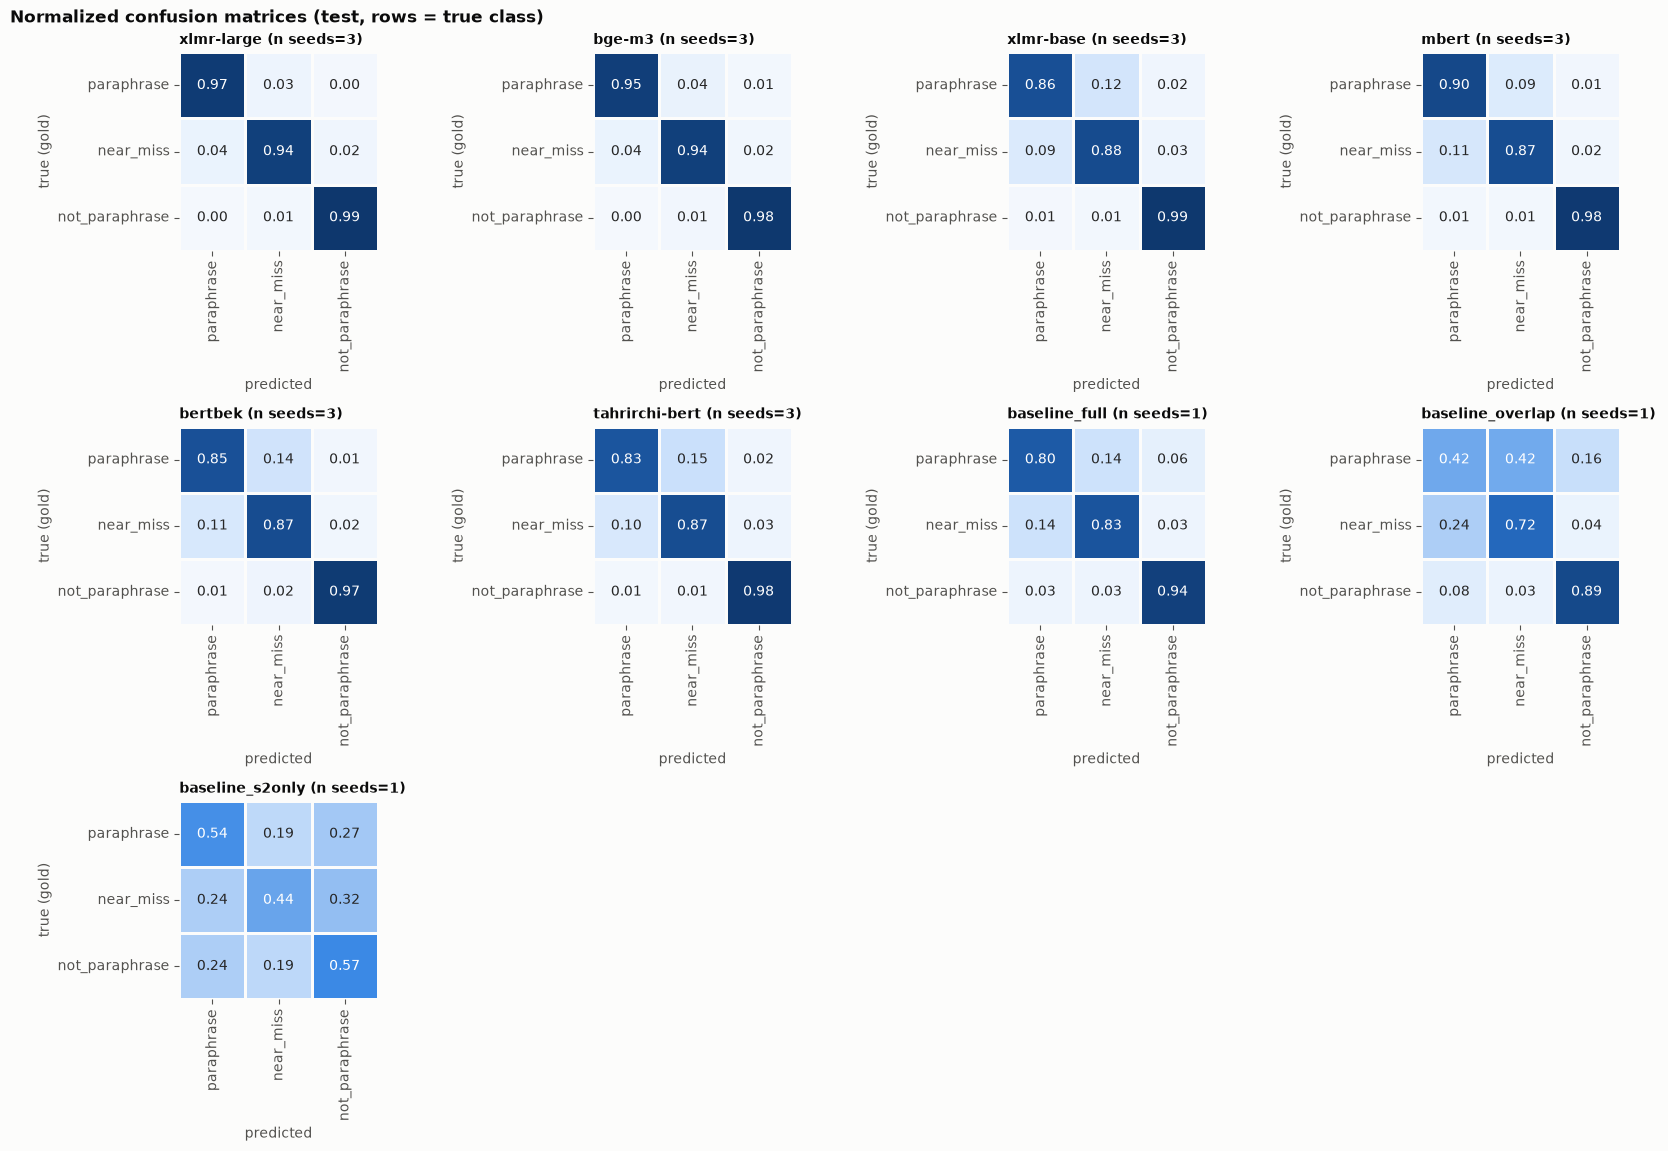

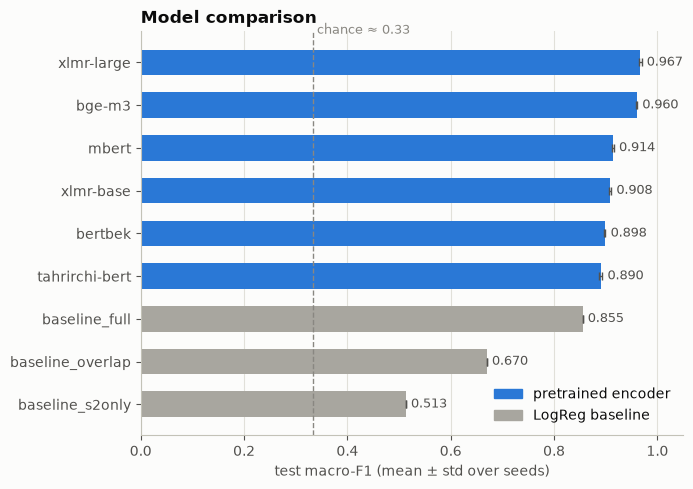

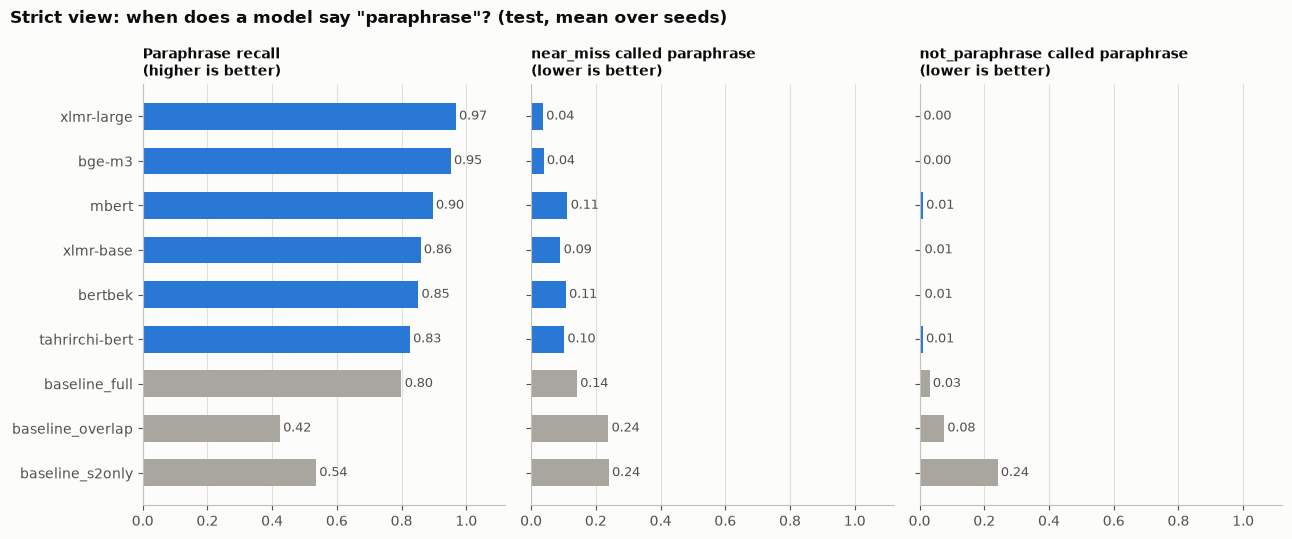

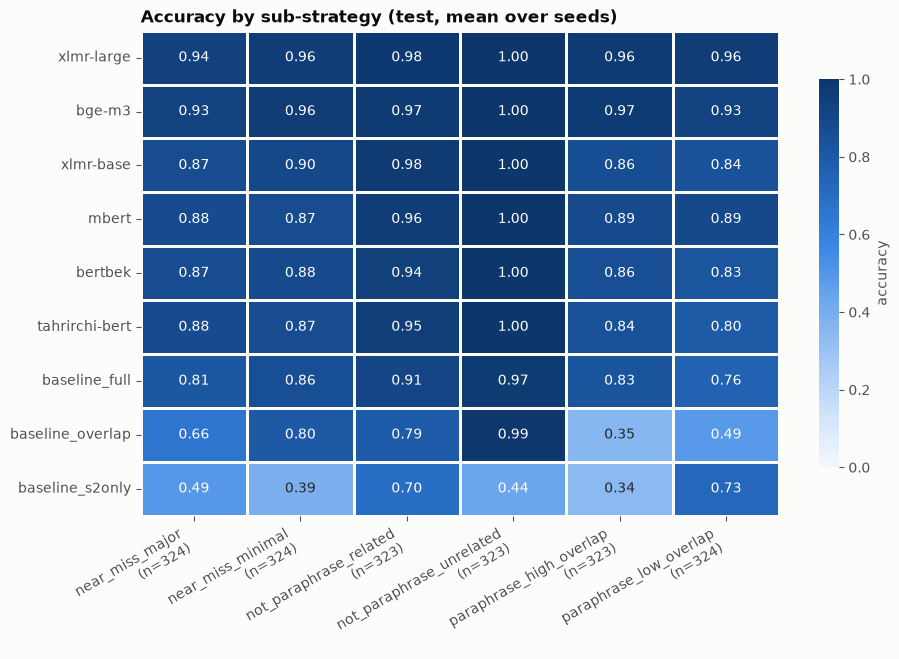

Figures saved to figs


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colors: one blue for encoders, muted gray for baselines, a single-hue blue ramp for heatmaps
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, GRAY = "#2a78d6", "#a8a69f"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
CHANCE = 1 / 3  # macro-F1 of uniform random guessing with 3 balanced classes


def bar_colors(models):
    return [GRAY if m.startswith("baseline") else BLUE for m in models]


def type_legend(ax):
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=BLUE, label="pretrained encoder"), Patch(color=GRAY, label="LogReg baseline")],
              frameon=False, loc="lower right")


# 11.1 Confusion matrices
cm_norm = {}
for model in MODEL_ORDER:
    counts = np.zeros((3, 3))
    for dev, test in PRED[model].values():
        counts += np.bincount(test_df["gold_id"] * 3 + test.argmax(1), minlength=9).reshape(3, 3)
    cm_norm[model] = counts / counts.sum(axis=1, keepdims=True)


def draw_cm(ax, model):
    sns.heatmap(cm_norm[model], ax=ax, annot=True, fmt=".2f", cmap=BLUE_RAMP, vmin=0, vmax=1, cbar=False,
                square=True, linewidths=2, linecolor=SURFACE, xticklabels=LABELS, yticklabels=LABELS)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true (gold)")
    ax.set_title(f"{model} (n seeds={len(PRED[model])})", fontsize=10)


for model in MODEL_ORDER:
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    draw_cm(ax, model)
    fig.savefig(os.path.join(FIGS_DIR, f"cm_{model}_{RUN_TAG}.png"))
    plt.close(fig)

ncols = min(4, len(MODEL_ORDER))
nrows = math.ceil(len(MODEL_ORDER) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
for ax, model in zip(axes.flat, MODEL_ORDER):
    draw_cm(ax, model)
for ax in axes.flat[len(MODEL_ORDER):]:
    ax.axis("off")
fig.suptitle("Normalized confusion matrices (test, rows = true class)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGS_DIR, f"cm_all_{RUN_TAG}.png"))
plt.show()

# 11.2 Model comparison: test macro-F1 (mean ± std over seeds), best at the top
order = summary.sort_values("test_macro_f1_mean").index.tolist()
fig, ax = plt.subplots(figsize=(7, 0.45 * len(order) + 1.2))
means, stds = summary.loc[order, "test_macro_f1_mean"], summary.loc[order, "test_macro_f1_std"].fillna(0)
ax.barh(order, means, xerr=stds, height=0.6, color=bar_colors(order),
        error_kw={"elinewidth": 1, "ecolor": INK_2, "capsize": 3})
for y, (m, s) in enumerate(zip(means, stds)):
    ax.text(m + s + 0.01, y, f"{m:.3f}", va="center", fontsize=9, color=INK_2)
ax.axvline(CHANCE, color=MUTED, linestyle="--", linewidth=1)
ax.text(CHANCE, len(order) - 0.4, " chance ≈ 0.33", color=MUTED, fontsize=9, va="bottom")
ax.set_xlim(0, 1.05)
ax.set_xlabel("test macro-F1 (mean ± std over seeds)")
ax.set_title("Model comparison")
ax.xaxis.grid(True, linewidth=0.8)
ax.set_axisbelow(True)
type_legend(ax)
fig.savefig(os.path.join(FIGS_DIR, f"model_comparison_{RUN_TAG}.png"))
plt.show()

# 11.3 Strict binary view as three small panels (same model order as 11.2)
panels = [("test_para_recall_mean", "Paraphrase recall", "higher is better"),
          ("test_near_miss_fpr_mean", "near_miss called paraphrase", "lower is better"),
          ("test_not_para_fpr_mean", "not_paraphrase called paraphrase", "lower is better")]
fig, axes = plt.subplots(1, 3, figsize=(13, 0.45 * len(order) + 1.4), sharey=True)
for ax, (col, title, direction) in zip(axes, panels):
    values = summary.loc[order, col]
    ax.barh(order, values, height=0.6, color=bar_colors(order))
    for y, v in enumerate(values):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9, color=INK_2)
    ax.set_xlim(0, 1.12)
    ax.set_title(f"{title}\n({direction})", fontsize=10)
    ax.xaxis.grid(True, linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Strict view: when does a model say \"paraphrase\"? (test, mean over seeds)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGS_DIR, f"strictness_{RUN_TAG}.png"))
plt.show()

# 11.4 Accuracy by sub_strategy (heatmap, models x sub-strategies)
sub_table = breakdown("sub_strategy")
heat = sub_table[MODEL_ORDER].T
heat.columns = [f"{c}\n(n={n})" for c, n in zip(sub_table.index, sub_table["n"])]
fig, ax = plt.subplots(figsize=(1.3 * heat.shape[1] + 2.5, 0.5 * heat.shape[0] + 1.8))
sns.heatmap(heat, ax=ax, annot=True, fmt=".2f", cmap=BLUE_RAMP, vmin=0, vmax=1, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "accuracy", "shrink": 0.8})
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Accuracy by sub-strategy (test, mean over seeds)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.savefig(os.path.join(FIGS_DIR, f"substrategy_heatmap_{RUN_TAG}.png"))
plt.show()
print("Figures saved to", FIGS_DIR)

## 12. Bootstrap confidence intervals and model selection
- 95% CIs for test macro-F1 by resampling **whole `source_sentence_id` groups** (pairs from the same source
  sentence are not independent, so resampling single rows would make the intervals too narrow).
  In each bootstrap sample we compute macro-F1 for every seed and average over seeds.
- The **best model is chosen by mean dev macro-F1**; its test score is reported once.
- Paired bootstrap: on the same resamples we compute (best − other). If the 95% CI of that difference
  contains 0, the two models are treated as a **tie**.

325 source groups in test, 1000 bootstrap samples
12.1 Test macro-F1 with 95% grouped-bootstrap CI (ordered by dev macro-F1)


,dev macro-F1,test macro-F1,CI low,CI high
xlmr-large,0.967,0.967,0.960,0.974
bge-m3,0.953,0.960,0.952,0.967
xlmr-base,0.911,0.908,0.897,0.919
mbert,0.905,0.914,0.904,0.925
bertbek,0.900,0.898,0.885,0.911
tahrirchi-bert,0.894,0.890,0.878,0.903
baseline_full,0.845,0.855,0.839,0.871
baseline_overlap,0.663,0.670,0.650,0.688
baseline_s2only,0.522,0.513,0.492,0.534



12.2 SELECTED BY DEV: xlmr-large (dev macro-F1 0.967)
     Its TEST macro-F1: 0.967  [95% CI 0.960 – 0.974]

12.3 Paired bootstrap: xlmr-large minus each other model (test macro-F1)


,other model,mean difference,diff CI low,diff CI high,verdict
0,bge-m3,0.007,0.001,0.013,xlmr-large better
1,xlmr-base,0.059,0.049,0.069,xlmr-large better
2,mbert,0.053,0.043,0.062,xlmr-large better
3,bertbek,0.069,0.057,0.082,xlmr-large better
4,tahrirchi-bert,0.077,0.065,0.089,xlmr-large better
5,baseline_full,0.112,0.096,0.127,xlmr-large better
6,baseline_overlap,0.298,0.278,0.316,xlmr-large better
7,baseline_s2only,0.454,0.433,0.475,xlmr-large better


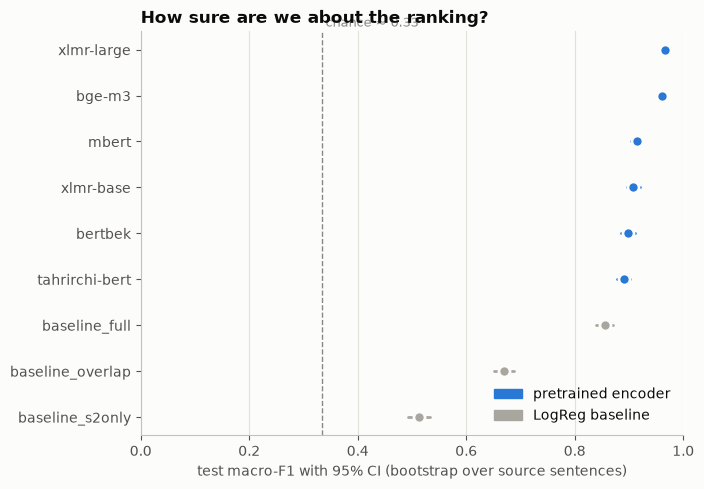

In [12]:
gold_test = test_df["gold_id"].to_numpy()
# rows without a source ID become their own group
group_ids = [sid if sid else f"row_{i}" for i, sid in enumerate(test_df["source_sentence_id"])]
group_codes, _ = pd.factorize(pd.Series(group_ids))
rows_of_group = [np.flatnonzero(group_codes == g) for g in range(group_codes.max() + 1)]
rng = np.random.default_rng(12345)
boot_samples = [np.concatenate([rows_of_group[g] for g in rng.integers(0, len(rows_of_group), len(rows_of_group))])
                for _ in range(N_BOOTSTRAP)]
print(f"{len(rows_of_group)} source groups in test, {N_BOOTSTRAP} bootstrap samples")

boot_scores = {}  # model -> array of N_BOOTSTRAP macro-F1 values (mean over seeds)
for model in MODEL_ORDER:
    test_preds = [test.argmax(1) for dev, test in PRED[model].values()]
    boot_scores[model] = np.array([np.mean([macro_f1(gold_test[idx], p[idx]) for p in test_preds])
                                   for idx in boot_samples])

ci_table = pd.DataFrame({
    "dev macro-F1": summary.loc[MODEL_ORDER, "dev_macro_f1_mean"],
    "test macro-F1": summary.loc[MODEL_ORDER, "test_macro_f1_mean"],
    "CI low": [np.percentile(boot_scores[m], 2.5) for m in MODEL_ORDER],
    "CI high": [np.percentile(boot_scores[m], 97.5) for m in MODEL_ORDER],
}, index=MODEL_ORDER)

BEST_MODEL = MODEL_ORDER[0]  # highest mean dev macro-F1
comparison = []
for model in MODEL_ORDER[1:]:
    diff = boot_scores[BEST_MODEL] - boot_scores[model]
    low, high = np.percentile(diff, [2.5, 97.5])
    verdict = "tie" if low <= 0 <= high else (f"{BEST_MODEL} better" if low > 0 else f"{model} better")
    comparison.append({"other model": model, "mean difference": diff.mean(), "diff CI low": low,
                       "diff CI high": high, "verdict": verdict})
comparison = pd.DataFrame(comparison)

print("12.1 Test macro-F1 with 95% grouped-bootstrap CI (ordered by dev macro-F1)")
display(ci_table.round(3))
ci_table.to_csv(os.path.join(RESULTS_DIR, f"bootstrap_ci_{RUN_TAG}.csv"))
best = ci_table.loc[BEST_MODEL]
print(f"\n12.2 SELECTED BY DEV: {BEST_MODEL} (dev macro-F1 {best['dev macro-F1']:.3f})")
print(f"     Its TEST macro-F1: {best['test macro-F1']:.3f}  [95% CI {best['CI low']:.3f} – {best['CI high']:.3f}]")
print(f"\n12.3 Paired bootstrap: {BEST_MODEL} minus each other model (test macro-F1)")
display(comparison.round(3))
comparison.to_csv(os.path.join(RESULTS_DIR, f"paired_bootstrap_{RUN_TAG}.csv"), index=False)

# Forest plot of the CIs
plot_order = ci_table.sort_values("test macro-F1").index.tolist()
fig, ax = plt.subplots(figsize=(7, 0.45 * len(plot_order) + 1.2))
for y, model in enumerate(plot_order):
    r = ci_table.loc[model]
    color = GRAY if model.startswith("baseline") else BLUE
    ax.plot([r["CI low"], r["CI high"]], [y, y], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(r["test macro-F1"], y, "o", markersize=8, color=color, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_yticks(range(len(plot_order)), plot_order)
ax.axvline(CHANCE, color=MUTED, linestyle="--", linewidth=1)
ax.text(CHANCE, len(plot_order) - 0.5, " chance ≈ 0.33", color=MUTED, fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("test macro-F1 with 95% CI (bootstrap over source sentences)")
ax.set_title("How sure are we about the ranking?")
ax.xaxis.grid(True, linewidth=0.8)
ax.set_axisbelow(True)
type_legend(ax)
fig.savefig(os.path.join(FIGS_DIR, f"bootstrap_ci_{RUN_TAG}.png"))
plt.show()

## 13. Error analysis export (sentences go to PRIVATE_OUT only, never printed)
For the selected model we average the softmax probabilities over seeds (`ensemble_pred`) and also keep
each seed's prediction. Three files are written to `PRIVATE_OUT`: all errors, paraphrase→near_miss,
and near_miss→paraphrase. This cell prints only counts and aggregated error rates.

In [13]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


if is_inside_project(PRIVATE_OUT):
    raise ValueError("PRIVATE_OUT must be outside the project folder.")
os.makedirs(PRIVATE_OUT, exist_ok=True)

seed_preds = {seed: test.argmax(1) for seed, (dev, test) in PRED[BEST_MODEL].items()}
mean_probs = np.mean([softmax(test) for dev, test in PRED[BEST_MODEL].values()], axis=0)
ensemble_pred = mean_probs.argmax(1)

export = test_df[["sentence_1", "sentence_2", "label", "verified", "verified_label", "gold", "sub_strategy",
                  "domain", "source_sentence_id", "source_in_train"]].copy()  # contains text: never display
export["ensemble_pred"] = [LABELS[i] for i in ensemble_pred]
for seed, pred in seed_preds.items():
    export[f"pred_seed{seed}"] = [LABELS[i] for i in pred]
export["seeds_wrong"] = sum((pred != gold_test).astype(int) for pred in seed_preds.values())
for i, label in enumerate(LABELS):
    export[f"prob_{label}"] = mean_probs[:, i].round(4)
for col in ["word_jaccard", "char3_jaccard", "number_mismatch", "length_ratio"]:
    export[col] = features["test"][col].round(3).to_numpy()

is_error = pd.Series(ensemble_pred != gold_test, index=export.index)
files = {
    "errors_all": export[is_error],
    "errors_paraphrase_as_near_miss": export[(gold_test == P_ID) & (ensemble_pred == NM_ID)],
    "errors_near_miss_as_paraphrase": export[(gold_test == NM_ID) & (ensemble_pred == P_ID)],
}
for name, frame in files.items():
    frame.sort_values(["gold", "ensemble_pred", "sub_strategy"]).to_csv(
        os.path.join(PRIVATE_OUT, f"{name}_{BEST_MODEL}_{RUN_TAG}.csv"), index=False, encoding="utf-8-sig")
    print(f"{name}: {len(frame)} rows written to PRIVATE_OUT")

print(f"\n13.1 {BEST_MODEL}: gold (rows) x ensemble prediction (columns), counts")
error_crosstab = pd.crosstab(export["gold"], export["ensemble_pred"], margins=True, margins_name="TOTAL")
display(error_crosstab)

print("\n13.2 Error rate by sub_strategy (counts and rates only)")
display(pd.DataFrame({"n": export.groupby(safe_category(export["sub_strategy"])).size(),
                      "error rate": is_error.groupby(safe_category(export["sub_strategy"])).mean()}).round(3))

print("\n13.3 Error rate by word overlap (quartiles) and by number mismatch, per gold class")
overlap_bin = pd.qcut(features["test"]["word_jaccard"], 4, duplicates="drop")
display(pd.crosstab([export["gold"]], overlap_bin, values=is_error, aggfunc="mean").round(3))
display(pd.crosstab(export["gold"], features["test"]["number_mismatch"].map({0.0: "same numbers", 1.0: "numbers differ"}),
                    values=is_error, aggfunc="mean").round(3))

errors_all: 55 rows written to PRIVATE_OUT
errors_paraphrase_as_near_miss: 15 rows written to PRIVATE_OUT
errors_near_miss_as_paraphrase: 23 rows written to PRIVATE_OUT

13.1 xlmr-large: gold (rows) x ensemble prediction (columns), counts


ensemble_pred,near_miss,not_paraphrase,paraphrase,TOTAL
gold,,,,
near_miss,617,10,23,650
not_paraphrase,4,642,1,647
paraphrase,15,2,627,644
TOTAL,636,654,651,1941



13.2 Error rate by sub_strategy (counts and rates only)


,n,error rate
sub_strategy,,
near_miss_major,324,0.049
near_miss_minimal,324,0.040
not_paraphrase_related,323,0.015
not_paraphrase_unrelated,323,0.000
paraphrase_high_overlap,323,0.028
paraphrase_low_overlap,324,0.037



13.3 Error rate by word overlap (quartiles) and by number mismatch, per gold class


word_jaccard,"(-0.001, 0.114]","(0.114, 0.333]","(0.333, 0.818]","(0.818, 1.0]"
gold,,,,
near_miss,0.833,0.110,0.033,0.030
not_paraphrase,0.005,0.005,0.050,NaN
paraphrase,0.024,0.010,0.050,0.025


number_mismatch,numbers differ,same numbers
gold,,
near_miss,0.038,0.053
not_paraphrase,0.000,0.013
paraphrase,0.037,0.026


## 14. Report (metrics only)
Writes `results/report_<RUN_TAG>.md` with the main tables, confidence intervals, breakdowns, error counts
and the figures. It contains no sentences, so it can be shared and used for the slides.
In VS Code, right-click the file and choose "Open Preview" to see it with the figures.

In [14]:
import datetime


def markdown_table(df, decimals=3):
    """Turn a DataFrame into a Markdown table (no extra packages needed)."""
    df = df.copy()
    index_name = df.index.name or ""
    df.index = df.index.map(str)
    df.index.name = index_name
    df = df.reset_index()

    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return "–" if np.isnan(value) else f"{value:.{decimals}f}"
        return str(value)

    lines = ["| " + " | ".join(str(c) for c in df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


selected = ci_table.loc[BEST_MODEL]
status_counts = runs["status"].value_counts().to_dict()
lines = [
    f"# Uzbek paraphrase detection: results ({'QUICK pipeline test' if QUICK else 'full experiment'})",
    "",
    f"Generated {datetime.date.today()} | run tag `{RUN_TAG}` | data fingerprint `{DATA_FINGERPRINT}`",
    "",
    f"- Rows: train {len(train_df)} (used for encoder training: {len(train_run_df)}), dev {len(dev_df)}, "
    f"test {len(test_df)}",
    f"- Encoders: seeds {SEEDS}, {NUM_EPOCHS} epoch(s), max length {MAX_LENGTH}, best epoch chosen on dev macro-F1",
    f"- Runs by status: {status_counts}",
    "- Gold label = `verified_label` when present and valid, otherwise `label` (training uses `label`).",
    "- All scores are on the **test** set unless marked dev; mean ± std over seeds.",
    "",
    "## Selected model",
    "",
    f"Chosen by mean **dev** macro-F1: **{BEST_MODEL}** (dev {selected['dev macro-F1']:.3f}). "
    f"Test macro-F1 **{selected['test macro-F1']:.3f}** "
    f"(95% CI {selected['CI low']:.3f}–{selected['CI high']:.3f}, bootstrap over source sentences).",
    "",
    "## 1. Main results (3 classes)", "", markdown_table(main_table), "",
    "## 2. Strict view: paraphrase vs rest", "",
    "Paraphrase recall should be high; the share of near_miss / not_paraphrase pairs called "
    "\"paraphrase\" should be low.", "", markdown_table(strict_table), "",
    "## 3. 95% confidence intervals (grouped bootstrap)", "", markdown_table(ci_table), "",
]
if len(comparison):
    lines += [f"Paired bootstrap, {BEST_MODEL} minus each other model. A CI that contains 0 means a tie.", "",
              markdown_table(comparison.set_index("other model")), ""]
lines += [
    "## 4. Test macro-F1 on subsets", "", markdown_table(robustness), "",
    "## 5. Accuracy by sub-strategy (n = test rows)", "", markdown_table(breakdown("sub_strategy")), "",
    "## 6. Accuracy by domain (n = test rows)", "", markdown_table(breakdown("domain")), "",
    f"## 7. Errors of {BEST_MODEL} (counts; rows = gold, columns = prediction)", "",
    markdown_table(error_crosstab), "",
]
failed = runs[runs["status"] == "error"]
if len(failed):
    lines += ["## Failed runs", "", markdown_table(pd.DataFrame({
        "seed": failed["seed"].to_numpy(),
        "error type": failed["error"].astype(str).str.split(":").str[0].to_numpy()},
        index=pd.Index(failed["model"], name="model"))), ""]
collapsed = runs[runs["status"] == "collapsed"]
if len(collapsed):
    lines += [f"Collapsed runs (dev macro-F1 < {COLLAPSE_THRESHOLD}, kept in the means): "
              + ", ".join(f"{m} seed {s}" for m, s in zip(collapsed["model"], collapsed["seed"])), ""]
if globals().get("choice") is not None:
    lines += ["## Tokenizer settings", "", "Apostrophe form used per model (fewest [UNK], then fewest tokens):", "",
              markdown_table(choice.set_index("model")), ""]
if globals().get("length_table") is not None:
    lines += [f"Pair length in tokens (share above MAX_LENGTH = {MAX_LENGTH} is truncated):", "",
              markdown_table(length_table.reset_index(level="split"), decimals=1), ""]
figures = sorted(f for f in os.listdir(FIGS_DIR) if f.endswith(f"_{RUN_TAG}.png"))
lines += ["## Figures", ""] + [f"![{f}](../{FIGS_DIR}/{f})" for f in figures]

report_path = os.path.join(RESULTS_DIR, f"report_{RUN_TAG}.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print(f"Report written to {report_path} ({len(lines)} lines, metrics only, no sentences).")

Report written to results\report_all.md (78 lines, metrics only, no sentences).
